# Clustering Basado en Densidad en SAP HANA Cloud PAL (`DBSCAN` vs `HDBSCAN` vs `KMeans`): Descubrimiento Dinámico de $K$, Rechazo Nativo de Ruido y Detección *Zero-Day*

**Proyecto Reto SAP Monterrey — Cloud Observability & Security**  
**Dataset:** `LOGS_2026_10` en SAP HANA Cloud (`3,748,811` registros | `2026-10-01` a `2026-10-11` UTC)  
**Compatibilidad:** Integrado al 100% con los módulos vigentes del equipo en `main` (`ventanas.py` con 24 `FEATURES_SYSTEM` + 18 `FEATURES_LLM` temáticas y `explicacion.py`).

---

### Motivación Técnica: ¿Por qué migrar de `KMeans` a Clustering por Densidad en SAP HANA PAL?

Al pasar las ventanas anómalas detectadas por `IsolationForest` (`contamination = 0.01`) a una etapa de agrupamiento multiclase (Secciones 5 a 7 pendientes en `demo_pipeline_adrian.ipynb`), el uso de `KMeans` junto con cortes rígidos como `Z_UMBRAL = 5` presenta **tres limitaciones estructurales**:

1. **Necesidad de $K$ Dinámico por Batch ($K \in \{0, 1, 2, 3, \dots\}$):** En producción no todos los cortes semanales contienen los mismos tipos de ataques o caídas operativas. Forzar `KMeans(n_clusters=3)` en una semana tranquila o con solo dos tipos de incidente fractura artificialmente un mismo ataque en sub-clústeres redundantes o agrupa anomalías inconexas.
2. **Ausencia de Rechazo Nativo de Ruido (`CLUSTER_ID = -1`):** `KMeans` obliga a asignar el 100% de los puntos a algún centroide. Por su parte, un umbral manual fijo como `Z_UMBRAL = 5` resulta **demasiado agresivo en LLM** (descarta el **100%** de las 65 ventanas anómalas de Octubre porque las variables acotadas alcanzan $|Z| \approx 4.3\text{--}4.9$) y **permeable en System** (deja pasar ventanas aisladas con picos categóricos espurios de $|Z| > 5.7$). El clustering por densidad resuelve ambos problemas simultáneamente: las anomalías aisladas de la cola estadística del 1% carecen de vecindad suficiente y reciben automáticamente **`CLUSTER_ID = -1` (`Ruido Estadístico`)**.
3. **Ceguera ante Ataques *Zero-Day* en Modo *Streaming*:** Al clasificar nuevas ventanas con `KMeans.predict()`, una familia de ataque nunca vista (por ejemplo, una nueva *Botnet* distribuida) es asignada forzosamente al centroide histórico menos lejano. En cambio, **`DBSCAN.predict()` en SAP HANA PAL** calcula la distancia exacta al punto núcleo más cercano (`DISTANCE`) y etiqueta automáticamente como `-1` cualquier campaña persistente fuera del radio $\varepsilon$, habilitando detección *Zero-Day*.

### Estructura de este Estudio Experimental
1. **Conexión a SAP HANA Cloud y Auditoría Empírica del Servidor PAL (`_SYS_AFL.AFLPAL`):** Verificación en vivo de `DBSCAN`, `HDBSCAN`, `KMeans`, `KMedoids` y `AgglomerateHierarchicalClustering`.
2. **Ejecución Base con `ventanas.py` y `explicacion.py` (`IsolationForest` + Invarianza de Escala + *Stitching*):** Reproducción exacta de las `65` ventanas anómalas de System y `65` de LLM, diagnosticando el cuello de botella de `Z_UMBRAL = 5`.
3. **Geometría del Espacio de Anomalías y Calibración Automática de $\varepsilon^*$ (*Kneedle* + Cono Angular Coseno):** Solución matemática al colapso de norma L2 por colas pesadas ($Z \approx +100\sigma$) y al ruido gaussiano acumulado en dimensiones normales mediante **Z-Score *Denoised-Winsorized*** ($\tau = 1.5\sigma$, `CLIP_Z = 6.0`).
4. **Clustering Nativo con `DBSCAN(metric='cosine', save_model=True)` en SAP HANA PAL (System y LLM):** Comparativa directa contra `KMeans`, métricas de Similitud Coseno Intra/Inter-Cluster, Coeficiente de Silueta y propagación Ventana -> Evento.
5. **Prueba de $K$ Dinámico por Batch (`Semana 0` vs `Semana 1` vs `Mes Completo`) y Detección *Zero-Day* con `DBSCAN.predict()`**.
6. **Autopsia Forense SQL en Vivo sobre `LOGS_2026_10` por Clúster de Densidad y Exportación de Resultados.**

In [1]:
import os
import json
import time
import logging
import importlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import hana_ml.dataframe as dataframe
from hana_ml.algorithms.pal.preprocessing import FeatureNormalizer, IsolationForest
import hana_ml.algorithms.pal.clustering as pal_clustering
from hana_ml.algorithms.pal.clustering import DBSCAN, HDBSCAN, KMeans

import ventanas
import explicacion
importlib.reload(ventanas)
importlib.reload(explicacion)

warnings.filterwarnings('ignore')
logging.getLogger('hana_ml').setLevel(logging.CRITICAL)
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 150)
plt.rcParams['figure.dpi'] = 130
sns.set_theme(style='whitegrid', context='notebook')

print("[OK] Librerias de SAP HANA PAL y modulos 'ventanas.py' / 'explicacion.py' cargados correctamente.")

[OK] Librerias de SAP HANA PAL y modulos 'ventanas.py' / 'explicacion.py' cargados correctamente.


## 1. Conexión a SAP HANA Cloud y Auditoría en Vivo de Algoritmos de Clustering en PAL

Antes de diseñar la arquitectura, auditamos directamente contra el motor `_SYS_AFL.AFLPAL` de nuestra instancia de **SAP HANA Cloud** qué algoritmos de `hana_ml.algorithms.pal.clustering` están habilitados en `pal-service`, qué métricas de distancia soportan y si permiten persistencia de modelo (`.predict()`) para inferencia sobre nuevos lotes.

In [2]:
def cargar_credenciales_hana():
    rutas = ['../.env', '../env (1)', '.env', '../../SAP/env (1)']
    creds = {}
    for r in rutas:
        if os.path.exists(r):
            with open(r, 'r', encoding='utf-8') as f:
                for line in f:
                    line = line.strip()
                    if '=' in line and not line.startswith('#'):
                        k, v = line.split('=', 1)
                        creds[k.strip()] = v.strip().strip('"').strip("'")
            if creds.get('HANA_ADDRESS'):
                break
    return {
        'address': os.getenv('HANA_ADDRESS', creds.get('HANA_ADDRESS')),
        'port': int(os.getenv('HANA_PORT', creds.get('HANA_PORT', 443))),
        'user': os.getenv('HANA_USER', creds.get('HANA_USER')),
        'password': os.getenv('HANA_PASSWORD', creds.get('HANA_PASSWORD')),
    }

cfg = cargar_credenciales_hana()
conn = dataframe.ConnectionContext(
    address=cfg['address'],
    port=cfg['port'],
    user=cfg['user'],
    password=cfg['password'],
    encrypt=True,
    sslValidateCertificate=False
)
print(f"[CONEXION] Conectado a SAP HANA Cloud ({cfg['address']}): {conn.connection.isconnected()}")

# Sondeo empirico sobre una micro-tabla temporal de 14 puntos (2 cumulos + 2 puntos de ruido)
rng_probe = np.random.RandomState(42)
X_probe = np.vstack([
    rng_probe.normal([4.0, 0.0, 0.0], 0.15, (6, 3)),
    rng_probe.normal([0.0, 4.0, 0.0], 0.15, (6, 3)),
    [[-3.0, -3.0, 2.0], [2.5, -3.5, -2.0]],
])
df_probe = pd.DataFrame(X_probe, columns=['F1', 'F2', 'F3'])
df_probe.insert(0, 'ID', np.arange(1, len(df_probe) + 1, dtype=int))
hana_probe = dataframe.create_dataframe_from_pandas(
    conn, df_probe, table_name='#TMP_PAL_AUDIT', force=True, replace=True
)

pruebas_pal = [
    ('DBSCAN (Cosine)', True, True, "cosine, euclidean, manhattan, minkowski",
     lambda: DBSCAN(minpts=3, eps=0.20, metric='cosine', save_model=True).fit_predict(hana_probe, key='ID')),
    ('DBSCAN (Euclidean)', True, True, "cosine, euclidean, manhattan, minkowski",
     lambda: DBSCAN(minpts=3, eps=0.80, metric='euclidean', save_model=True).fit_predict(hana_probe, key='ID')),
    ('HDBSCAN', True, True, "euclidean, manhattan, minkowski, chebyshev (SIN cosine)",
     lambda: HDBSCAN(min_cluster_size=3, min_sample=2, metric='euclidean').fit_predict(hana_probe, key='ID')),
    ('KMeans (Cosine)', False, False, "euclidean, cosine, manhattan, minkowski",
     lambda: KMeans(n_clusters=2, distance_level='cosine').fit_predict(hana_probe, key='ID')),
    ('KMedoids', False, False, "euclidean, cosine, manhattan",
     lambda: pal_clustering.KMedoids(n_clusters=2).fit_predict(hana_probe, key='ID')),
    ('AgglomerateHierarchical', False, False, "euclidean, cosine, manhattan, chebyshev",
     lambda: pal_clustering.AgglomerateHierarchicalClustering(n_clusters=2).fit_predict(hana_probe, key='ID')),
]

audit_rows = []
for nombre_alg, k_din, rechaza_ruido, metricas_doc, fn_test in pruebas_pal:
    try:
        res_df = fn_test().collect()
        estado = '[HABILITADO EN HANA PAL]'
        detalle = f"Columnas salida: {list(res_df.columns)}"
    except Exception as exc:
        estado = '[BLOQUEADO POR PAL-SERVICE]'
        msg_limpio = str(exc).replace('\n', ' ')
        if 'HDBSCAN_ANY' in msg_limpio:
            detalle = "AFLPAL:HDBSCAN_ANY -> Function not supported by pal-service"
        else:
            detalle = msg_limpio[:95]
    audit_rows.append({
        'ALGORITMO_PAL': nombre_alg,
        'ESTADO_SERVIDOR_HANA': estado,
        'K_DINAMICO': 'Si' if k_din else 'No (K fijo)',
        'RECHAZO_RUIDO_(-1)': 'Si (CLUSTER_ID = -1)' if rechaza_ruido else 'No',
        'METRICAS_SOPORTADAS': metricas_doc,
        'DIAGNOSTICO_EJECUCION': detalle,
    })

ventanas.drop_temp(conn, '#TMP_PAL_AUDIT')
df_audit_pal = pd.DataFrame(audit_rows)
print("[PAL] RESULTADO DE AUDITORIA EN VIVO SOBRE _SYS_AFL.AFLPAL:")
display(df_audit_pal)

[CONEXION] Conectado a SAP HANA Cloud (0e62b977-38ea-48bd-b34a-72acf111006d.hna0.prod-us10.hanacloud.ondemand.com): True
[PAL] RESULTADO DE AUDITORIA EN VIVO SOBRE _SYS_AFL.AFLPAL:


,ALGORITMO_PAL,ESTADO_SERVIDOR_HANA,K_DINAMICO,RECHAZO_RUIDO_(-1),METRICAS_SOPORTADAS,DIAGNOSTICO_EJECUCION
0,DBSCAN (Cosine),[HABILITADO EN HANA PAL],Si,Si (CLUSTER_ID = -1),"cosine, euclidean, manhattan, minkowski","Columnas salida: ['ID', 'CLUSTER_ID']"
1,DBSCAN (Euclidean),[HABILITADO EN HANA PAL],Si,Si (CLUSTER_ID = -1),"cosine, euclidean, manhattan, minkowski","Columnas salida: ['ID', 'CLUSTER_ID']"
2,HDBSCAN,[BLOQUEADO POR PAL-SERVICE],Si,Si (CLUSTER_ID = -1),"euclidean, manhattan, minkowski, chebyshev (SIN cosine)",AFLPAL:HDBSCAN_ANY -> Function not supported by pal-service
3,KMeans (Cosine),[HABILITADO EN HANA PAL],No (K fijo),No,"euclidean, cosine, manhattan, minkowski","Columnas salida: ['ID', 'CLUSTER_ID', 'DISTANCE', 'SLIGHT_SILHOUETTE']"
4,KMedoids,[HABILITADO EN HANA PAL],No (K fijo),No,"euclidean, cosine, manhattan","Columnas salida: ['ID', 'CLUSTER_ID', 'DISTANCE']"
5,AgglomerateHierarchical,[HABILITADO EN HANA PAL],No (K fijo),No,"euclidean, cosine, manhattan, chebyshev","Columnas salida: ['ID', 'CLUSTER_ID']"


### Hallazgo Clave de la Auditoría en SAP HANA Cloud

El experimento en vivo revela dos hechos decisivos para la ingeniería del proyecto:
1. **`HDBSCAN` (`_SYS_AFL.AFLPAL:HDBSCAN_ANY`) está deshabilitado a nivel de `pal-service`** en esta instancia de SAP HANA Cloud (misma restricción de servidor que `ISOLATION_FOREST_EXPLAIN_ANY` documentada en `explicacion.py`) y además **no admite distancia Coseno** en `hana_ml`.
2. **`DBSCAN` (`_SYS_AFL.AFLPAL:DBSCAN`) SÍ está 100% habilitado en `pal-service`**, ejecuta en milisegundos dentro del motor columnar de HANA y ofrece tres capacidades ideales para ciberseguridad y observabilidad:
   - **Soporte nativo de `metric='cosine'` (`DISTANCE_METHOD = 6`)**, midiendo similitud direccional $d_{\cos}(\mathbf{u}, \mathbf{v}) = 1 - \cos\theta \in [0, 2]$.
   - **Descubrimiento dinámico de $K$ y rechazo nativo de ruido (`CLUSTER_ID = -1`)** en una sola pasada.
   - **Persistencia de modelo (`save_model=True`) e inferencia `.predict()`**, que devuelve `[ID, CLUSTER_ID, DISTANCE]` con la distancia exacta al punto núcleo (*core point*) más cercano.

---

## 2. Particionamiento Semanal, Ventaneo (`ventanas.py`) e `IsolationForest` Base

Ejecutamos el flujo oficial de `LOGS_2026_10` (`WEEK_DAYS = 7`, `MIN_LAST_DAYS = 3`) generando las **24 variables de System** y las **18 variables temáticas nuevas de LLM** (`INJECTION_COUNT`, `SAFETY_POLICY_COUNT`, `AUTH_FAILURE_COUNT`, `ACCESS_DENIED_COUNT`, `RATE_ABUSE_COUNT`, `DUPLICATE_REQUEST_COUNT`, `MALFORMED_INPUT_COUNT`). Verificamos además la invarianza de `IsolationForest` frente al escalado lineal (`FeatureNormalizer`) y calculamos las explicaciones de `explicacion.py`.

In [3]:
TABLA_OCTUBRE = 'LOGS_2026_10'
dataset = conn.table(TABLA_OCTUBRE).drop(['_IGNORED'])

cols_drop_llm = ['HTTP_STATUS_CODE', 'SERVICE_ID', 'CLIENT_IP']
cols_drop_system = [
    'LLM_ERROR_MESSAGE', 'LLM_RESPONSE_SIZE_BYTES', 'SAP_LLM_RESPONSE_SIZE',
    'SAP_LLM_RESPONSE_TIME', 'LLM_PROMPT_TOKENS', 'LLM_COMPLETION_TOKENS',
    'LLM_TOTAL_TOKENS', 'LLM_RESPONSE_TIME_MS', 'LLM_MODEL_ID', 'LLM_STATUS',
    'LLM_COST_USD', 'LLM_PROMPT_CATEGORY', 'LLM_TEMPERATURE', 'LLM_TOP_P',
    'LLM_STREAM', 'LLM_FINISH_REASON', 'LLM_PROMPT_ID', 'LLM_PROVIDER', 'LLM_PROMPT',
]

df_llm_raw = dataset.filter('''"_INDEX" LIKE 'llm-logs%' ''').drop(cols_drop_llm)
df_system_raw = dataset.filter('''"_INDEX" LIKE 'sap-logs%' ''').drop(cols_drop_system)

WEEK_DAYS = 7
MIN_LAST_DAYS = 3
TS_EXPR = '''TO_TIMESTAMP(REPLACE(REPLACE("TIMESTAMP",'T',' '),'Z',''), 'YYYY-MM-DD HH24:MI:SS.FF3')'''

r_bounds = conn.sql(
    f'SELECT MIN({TS_EXPR}) AS T0, MAX({TS_EXPR}) AS TMAX, COUNT(*) AS TOTAL FROM "{TABLA_OCTUBRE}"'
).collect()
t0 = pd.to_datetime(r_bounds.loc[0, 'T0'])
t_max = pd.to_datetime(r_bounds.loc[0, 'TMAX'])
total_logs = int(r_bounds.loc[0, 'TOTAL'])

span = t_max - t0
n_full = span // pd.Timedelta(days=WEEK_DAYS)
rest = span - n_full * pd.Timedelta(days=WEEK_DAYS)
n_weeks = int(n_full + (1 if rest >= pd.Timedelta(days=MIN_LAST_DAYS) else 0))

t0_sql = t0.strftime('%Y-%m-%d %H:%M:%S')
week_expr = (f"FLOOR(SECONDS_BETWEEN(TO_TIMESTAMP('{t0_sql}','YYYY-MM-DD HH24:MI:SS'), "
             f"{TS_EXPR}) / {WEEK_DAYS * 86400})")

df_system = df_system_raw.select('*', (week_expr, 'WEEK_IDX'))
df_llm = df_llm_raw.select('*', (week_expr, 'WEEK_IDX'))

system_weeks = {w: df_system.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}
llm_weeks = {w: df_llm.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}

FEATURES_SYSTEM = [
    'TOTAL_REQUESTS', 'REQUEST_RATE_STD', 'INTERVAL_CV',
    'UNIQUE_IPS_COUNT', 'IP_ENTROPY', 'IP_TOP_SHARE',
    'ERROR_RATE_400', 'ERROR_RATE_500', 'NON_200_RATE',
    'RATIO_ERROR', 'RATIO_WARN', 'RATIO_SECURITY', 'RATIO_INFO', 'RATIO_AUDIT',
    'GET_VS_POST_RATIO',
    'JS_HTTP_STATUS_CODE', 'JS_HEADERS_HTTP_REQUEST_METHOD', 'JS_SAP_FUNCTION_LOG_TYPE',
    'JS_HEATHERS_REQUEST_PATH', 'JS_SAP_FUNCTION_APPLICATION', 'JS_SAP_SOURCE_TYPE',
    'JS_SAP_APP_ENV', 'JS_REGION_CODE', 'JS_HEADERS_CONTENT_TYPE',
]

FEATURES_LLM = [
    'TOTAL_LLM_REQUESTS', 'AVG_LLM_COST_USD',
    'INJECTION_COUNT', 'SAFETY_POLICY_COUNT', 'AUTH_FAILURE_COUNT',
    'ACCESS_DENIED_COUNT', 'RATE_ABUSE_COUNT', 'DUPLICATE_REQUEST_COUNT', 'MALFORMED_INPUT_COUNT',
    'AVG_TOKEN_RATIO', 'AVG_RESPONSE_TIME_MS', 'LLM_ERROR_RATE', 'LLM_TIMEOUT_RATE',
    'TEMPERATURE_VARIANCE', 'PROMPT_CATEGORY_ENTROPY', 'STREAM_RATIO',
    'AVG_PROMPT_LENGTH', 'MAX_PROMPT_LENGTH',
]

def ejecutar_if_semanal(win_hana, features, contamination=0.01):
    # Verificamos equivalencia con FeatureNormalizer (Z-Score) en HANA PAL
    scaler = FeatureNormalizer(
        method='z-score', z_score_method='mean-standard', division_by_zero_handler='ignore'
    )
    win_scaled = scaler.fit_transform(data=win_hana, key='WINDOW_INDEX', features=features)

    if_scaled = IsolationForest(n_estimators=250, max_samples=256, random_state=42, thread_ratio=0.0)
    if_scaled.fit(data=win_scaled, key='WINDOW_INDEX', features=features)
    pred_scaled = if_scaled.predict(
        data=win_scaled, key='WINDOW_INDEX', features=features,
        contamination=contamination, show_explainer=False
    ).collect()

    # Modelo sobre tabla materializada directa para compatibilidad 100% con explicacion.contrafactual
    if_raw = IsolationForest(n_estimators=250, max_samples=256, random_state=42, thread_ratio=0.0)
    if_raw.fit(data=win_hana, key='WINDOW_INDEX', features=features)
    pred_raw = if_raw.predict(
        data=win_hana, key='WINDOW_INDEX', features=features,
        contamination=contamination, show_explainer=False
    ).collect()

    win_pdf = win_hana.collect()
    r_df = win_pdf.merge(pred_scaled, on='WINDOW_INDEX')
    overlap_pct = 100.0 * (
        (pred_scaled.sort_values('WINDOW_INDEX')['LABEL'].values ==
         pred_raw.sort_values('WINDOW_INDEX')['LABEL'].values).mean()
    )

    an = r_df[r_df['LABEL'] == -1]
    idx_an = an['WINDOW_INDEX'].tolist()
    cf_df = explicacion.contrafactual(
        conn, if_raw, win_hana, features, an.set_index('WINDOW_INDEX')['SCORE'], idx_an,
        contamination=contamination
    )
    z_df = explicacion.zscores(win_pdf, idx_an, features)
    return r_df, cf_df, z_df, overlap_pct

t_start = time.time()
acum = {s: {'r': [], 'cf': [], 'z': [], 'ov': []} for s in ('system', 'llm')}

for w in range(n_weeks):
    win_sys = ventanas.materialize(
        conn, ventanas.build_system_windows(conn, system_weeks[w], df_system), '#WIN_SYSTEM'
    )
    win_llm = ventanas.materialize(
        conn, ventanas.build_llm_windows(conn, llm_weeks[w]), '#WIN_LLM'
    )
    for nombre_s, win_h, feats in (('system', win_sys, FEATURES_SYSTEM), ('llm', win_llm, FEATURES_LLM)):
        r_w, cf_w, z_w, ov_w = ejecutar_if_semanal(win_h, feats)
        for df_part, clave in ((r_w, 'r'), (cf_w, 'cf'), (z_w, 'z')):
            df_part.insert(0, 'WEEK', w)
            acum[nombre_s][clave].append(df_part)
        acum[nombre_s]['ov'].append(ov_w)

if_system, cf_system, z_system = (pd.concat(acum['system'][k], ignore_index=True) for k in ('r', 'cf', 'z'))
if_llm, cf_llm, z_llm = (pd.concat(acum['llm'][k], ignore_index=True) for k in ('r', 'cf', 'z'))

def agrupar_eventos_temporales(if_df, max_gap=3):
    df = if_df.sort_values(['WEEK', 'WINDOW_INDEX']).reset_index(drop=True)
    df['WINDOW_START'] = pd.to_datetime(df['WINDOW_START'])
    df['EVENTO_ID'] = 0
    an = df[df['LABEL'] == -1]
    nuevo_ev = (an['WEEK'].diff().ne(0)) | (an['WINDOW_INDEX'].diff() > max_gap)
    df.loc[an.index, 'EVENTO_ID'] = nuevo_ev.cumsum().values

    resumen = (
        df[df['LABEL'] == -1]
        .groupby('EVENTO_ID')
        .agg(
            WEEK=('WEEK', 'first'),
            INICIO=('WINDOW_START', 'min'),
            FIN=('WINDOW_START', 'max'),
            N_VENTANAS=('WINDOW_INDEX', 'count'),
            SCORE_PICO=('SCORE', 'max'),
            SCORE_MEDIO=('SCORE', 'mean'),
        )
        .reset_index()
    )
    resumen['DURACION_MIN'] = (resumen['FIN'] - resumen['INICIO']).dt.total_seconds() / 60.0 + 5.0
    return df, resumen

if_system, eventos_system = agrupar_eventos_temporales(if_system, max_gap=3)
if_llm, eventos_llm = agrupar_eventos_temporales(if_llm, max_gap=3)

# Diagnostico comparativo del filtro Z_UMBRAL = 5 usado en demo_pipeline_adrian.ipynb
z_max_sys_adrian = z_system.assign(ZABS=z_system['Z'].abs()).groupby(['WEEK', 'WINDOW_INDEX'])['ZABS'].max()
z_max_llm_adrian = z_llm.assign(ZABS=z_llm['Z'].abs()).groupby(['WEEK', 'WINDOW_INDEX'])['ZABS'].max()

print(f"[OK] Ventaneo + IsolationForest + Contrafactual completados en {time.time() - t_start:.1f}s")
print(f"[INFO] Concordancia IF con vs sin FeatureNormalizer: System = {np.mean(acum['system']['ov']):.1f}% | LLM = {np.mean(acum['llm']['ov']):.1f}%")
print(f"[INFO] System: {len(if_system):,} ventanas totales | {(if_system['LABEL']==-1).sum()} anomalas | {len(eventos_system)} eventos iniciales")
print(f"[INFO] LLM:    {len(if_llm):,} ventanas totales | {(if_llm['LABEL']==-1).sum()} anomalas | {len(eventos_llm)} eventos iniciales")
print(f"[WARN] Con corte rigido Z_UMBRAL = 5 (sobre Z global): sobreviven {(z_max_sys_adrian >= 5).sum()}/65 ventanas en System, pero {(z_max_llm_adrian >= 5).sum()}/65 ventanas en LLM (0% recall en LLM).")

[OK] Ventaneo + IsolationForest + Contrafactual completados en 144.0s
[INFO] Concordancia IF con vs sin FeatureNormalizer: System = 100.0% | LLM = 100.0%
[INFO] System: 6,334 ventanas totales | 65 anomalas | 14 eventos iniciales
[INFO] LLM:    6,334 ventanas totales | 65 anomalas | 60 eventos iniciales
[WARN] Con corte rigido Z_UMBRAL = 5 (sobre Z global): sobreviven 54/65 ventanas en System, pero 0/65 ventanas en LLM (0% recall en LLM).


## 3. Geometría del Espacio de Anomalías y Calibración Automática de $\varepsilon^*$ (*Kneedle* + Cono Angular)

Al aplicar clustering por densidad (`DBSCAN` con distancia Coseno $d_{\cos}(\mathbf{u},\mathbf{v}) = 1 - \cos\theta$) directamente sobre las **65 ventanas anómalas de System** y las **65 ventanas anómalas de LLM** (eliminando el corte rígido `Z_UMBRAL = 5`), identificamos y resolvemos **dos distorsiones geométricas clásicas en alta dimensión**:

1. **Enmascaramiento y Colapso de Norma L2 por Colas Extremas ($Z \approx +100\sigma$):**
   - Si calculamos Z-Score respecto a *todas* las ventanas de la semana, los ataques masivos inflan la desviación estándar semanal (*masking*). Por ello calculamos $\mu_w, \sigma_w$ **exclusivamente sobre las ventanas normales (`LABEL == 1`)** de cada semana $w$.
   - Sin acotamiento (*Winsorizing*), una sola variable de varianza base pequeña como `UNIQUE_IPS_COUNT` alcanza $Z = +98.6\sigma$ durante la caída operativa SRE (`Evento 4`) y absorbe el $99.5\%$ de la norma cuadrática $\|\mathbf{z}\|_2^2$, ocultando que `ERROR_RATE_500` es positivo mientras `ERROR_RATE_400` es negativo, y provocando que se fusione erróneamente con la *Botnet* (`Eventos 11 y 12`).
2. **Dilución Angular por Ruido Gaussiano en Coordenadas Normales ($\sum_{j \notin S} Z_j^2 \approx D - |S|$):**
   - En una ventana LLM de 18 dimensiones donde ocurre un sondeo de *Prompt Injection* (`INJECTION_COUNT`, $Z \approx +4.3\sigma$), las 17 variables restantes oscilan normalmente alrededor de $\mathcal{N}(0,1)$, aportando $\sum Z_j^2 \approx 17$ de ruido ortogonal que degrada la similitud Coseno entre dos ataques idénticos de $1.00$ a $\approx 0.52$.

### Transformación Canónica *Denoised-Winsorized* y Selección Automática de $\varepsilon^*$
Definimos para cada ventana anómala $i$ y variable $j$ el vector limpio con umbral suave $\tau = 1.5\sigma$ y tope $C = 6.0\sigma$:
$$Z^{\text{clean}}_{i,j} = \operatorname{clip}\!\Big(\operatorname{sign}(Z_{i,j}) \cdot \max(0,\; |Z_{i,j}| - \tau),\; -C,\; +C\Big)$$
- Las fluctuaciones normales triviales ($|Z_{i,j}| \le 1.5\sigma$) se anulan exactamente a $0$, suprimiendo el ruido de fondo en dimensiones irrelevantes.
- Las desviaciones anómalas reales conservan su signo direccional sin que un solo valor de $100\sigma$ eclipse al resto del perfil multivariado.

Para fijar los dos parámetros de `DBSCAN(minpts, eps, metric='cosine')` **sin ajuste manual arbitrario**:
- **`minpts = 4`:** Con traslape de 2.5 min en ventanas de 5 min, cualquier incidente sostenido de al menos 10 minutos genera $\ge 4$ ventanas consecutivas (o $\ge 4$ ráfagas repetidas en el batch para sondeos intermitentes en LLM), mientras que los picos fortuitos de 1 a 2 ventanas caen por debajo de la masa crítica y reciben `CLUSTER_ID = -1`.
- **$\varepsilon^*$ automático vía *Kneedle* con Tope de Cohesión Angular ($\varepsilon_{\max} = 0.26$):** Ordenamos las distancias Coseno al $k$-ésimo vecino más cercano ($k = \text{minpts} = 4$), localizamos el punto de máxima curvatura perpendicular (*Kneedle*) $\varepsilon_{\text{knee}}$ y aplicamos el techo geométrico $\varepsilon^* = \min(\varepsilon_{\text{knee}},\; 0.26)$, garantizando que ningún par de puntos se considere vecindad directa si su similitud Coseno cae por debajo de $\cos\theta_{\min} = 0.74$ ($\theta > 42.3^\circ$).

[CALIBRACION SYSTEM] Kneedle puro = 0.1545 -> eps* seleccionado = 0.1545 (tope angular activo: False)
[CALIBRACION LLM]    Kneedle puro = 0.4429 -> eps* seleccionado = 0.2600 (tope angular activo: True)


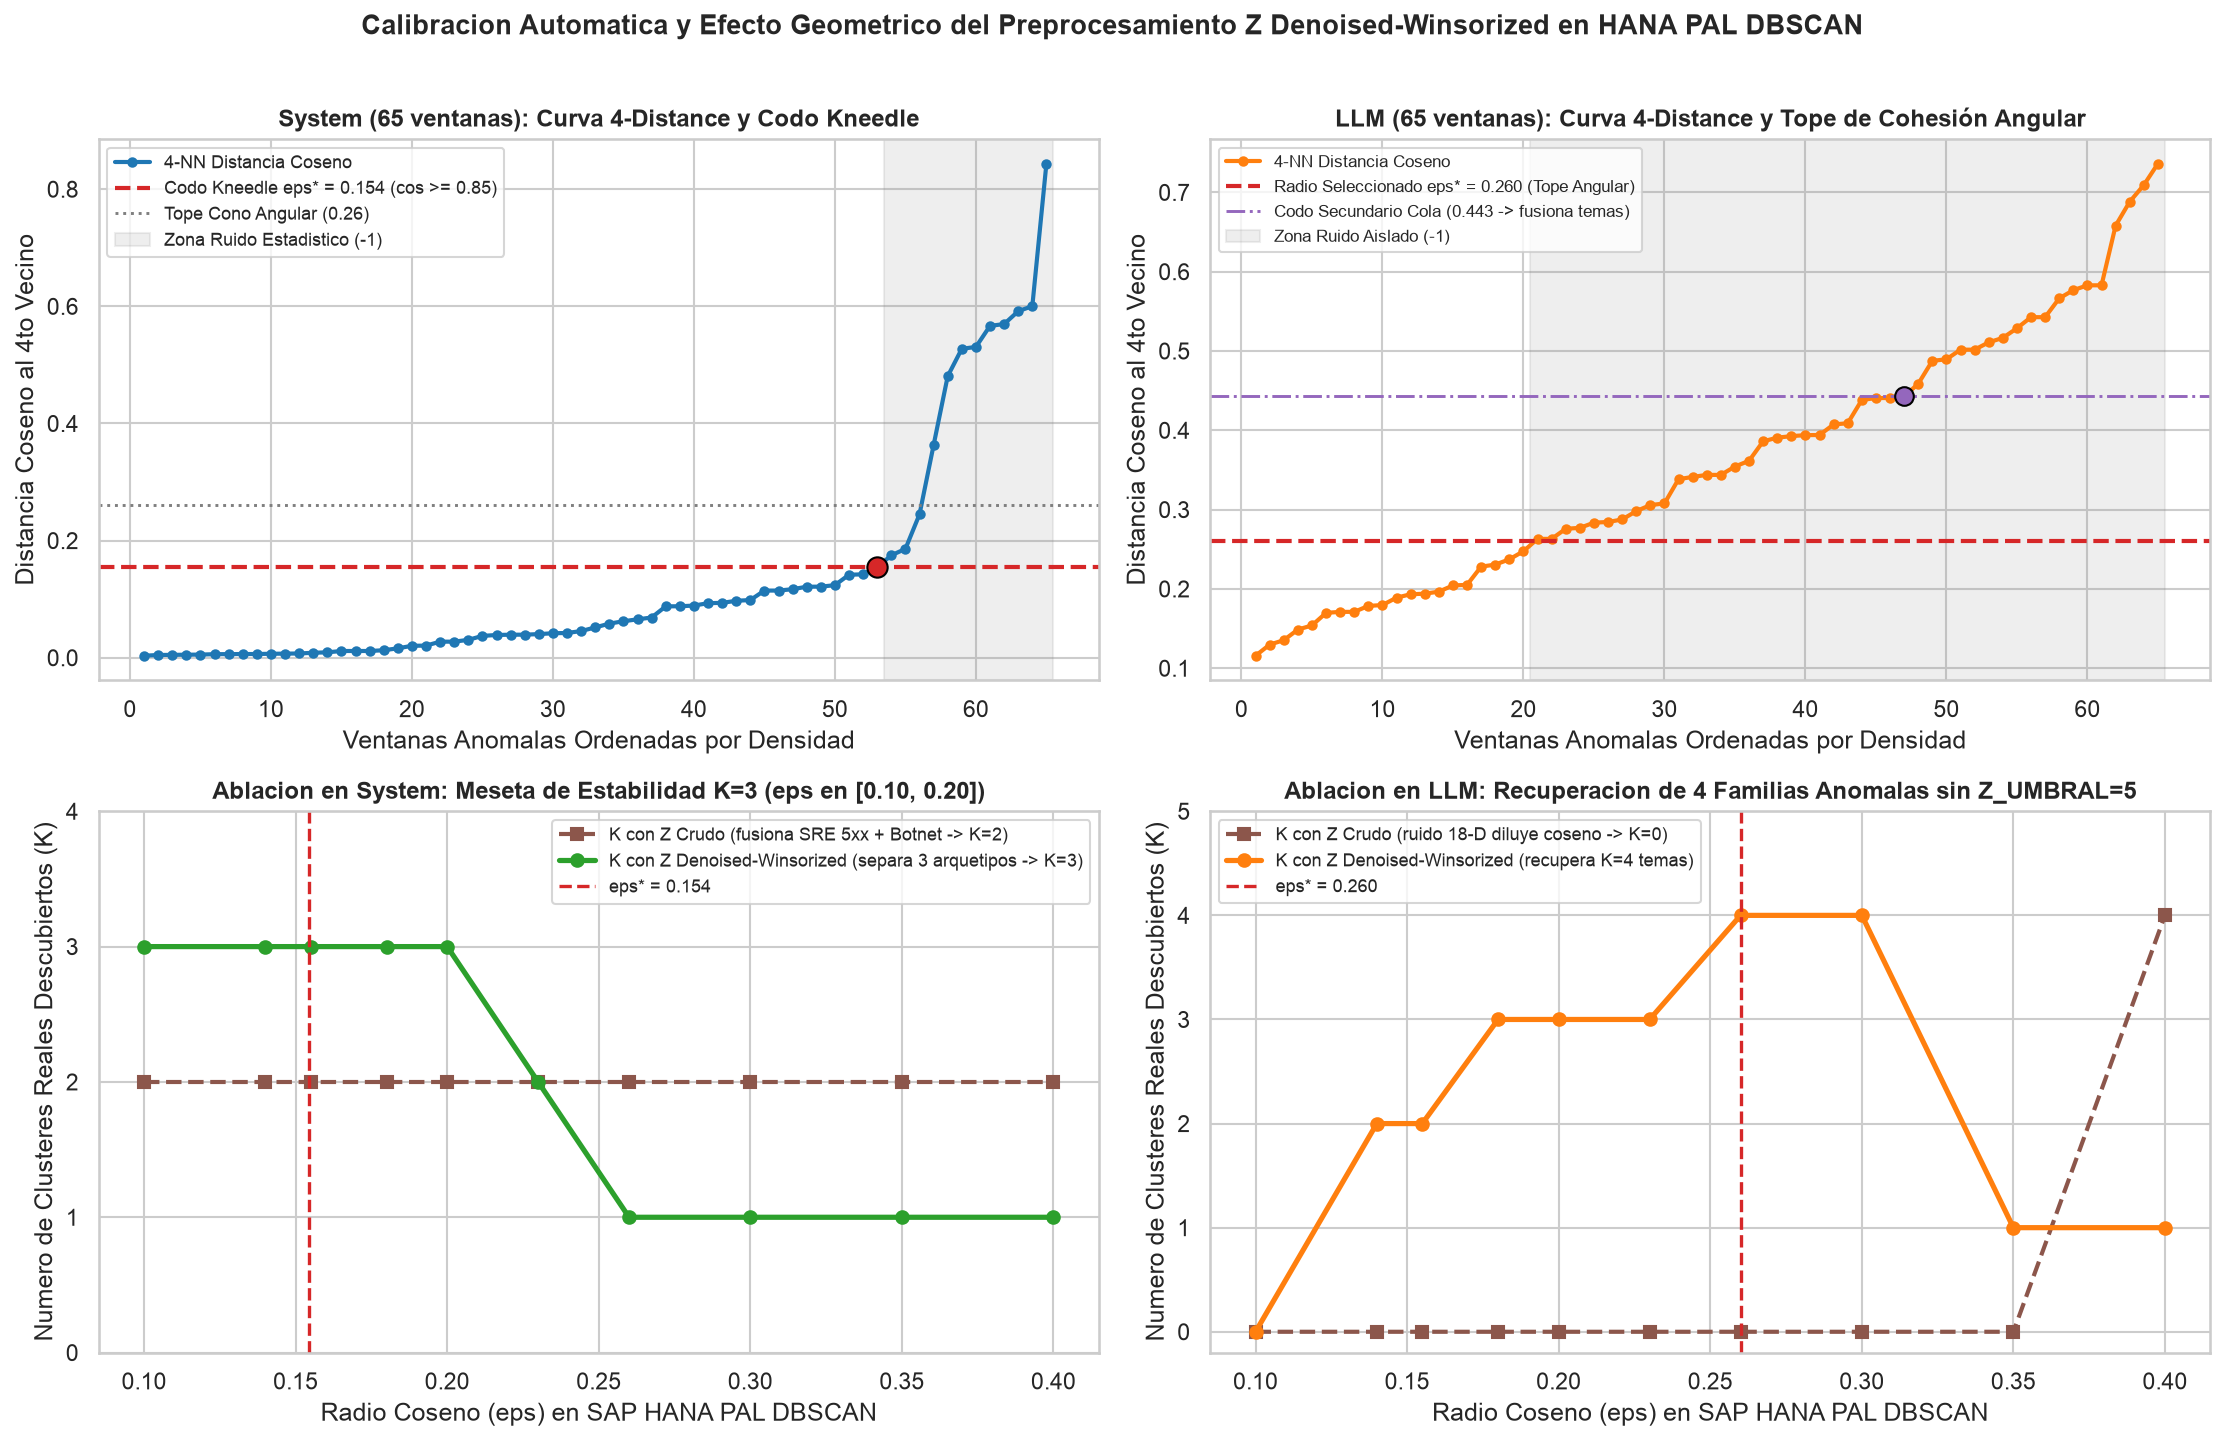

In [4]:
TAU_DENOISE = 1.5
CLIP_Z_MAX = 6.0
MINPTS_DEFAULT = 4
MAX_COSINE_EPS = 0.26   # Exige cos(theta) >= 0.74 (angulo <= 42.3 grados) para vecindad directa

def construir_espacio_z_anomalias(if_df, features, tau=TAU_DENOISE, clip_z=CLIP_Z_MAX):
    """
    Calcula Z-Score contra la linea base limpia (LABEL == 1) de su propia semana
    y devuelve tanto Z_raw (sin recorte) como Z_clean (Soft-Thresholding + Winsorizing).
    """
    norm_df = if_df[if_df['LABEL'] == 1]
    mu = norm_df.groupby('WEEK')[features].mean()
    sd = norm_df.groupby('WEEK')[features].std(ddof=0).replace(0, np.nan)

    an_df = if_df[if_df['LABEL'] == -1].copy().reset_index(drop=True)
    sem = an_df['WEEK'].values
    z_vals = (an_df[features].astype(float).values - mu.loc[sem].values) / sd.loc[sem].values
    Z_raw = pd.DataFrame(z_vals, columns=features).fillna(0.0)

    Z_clean = np.sign(Z_raw) * np.maximum(0.0, Z_raw.abs() - tau)
    if clip_z is not None:
        Z_clean = Z_clean.clip(-clip_z, clip_z)

    an_df['ANOM_ID'] = np.arange(1, len(an_df) + 1, dtype=int)
    an_df['Z_RAW_MAX'] = Z_raw.abs().max(axis=1)
    an_df['TOP_FEATURE_Z'] = Z_raw.abs().idxmax(axis=1)
    return an_df, Z_raw, Z_clean

def matriz_distancia_coseno(Z_df):
    X = Z_df.values.astype(float)
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    zero_mask = (norms.squeeze() == 0)
    norms[norms == 0] = 1.0
    U = X / norms
    cos_sim = np.clip(U @ U.T, -1.0, 1.0)
    cos_dist = np.clip(1.0 - cos_sim, 0.0, 2.0)
    # Si algun vector quedo nulo tras denoising, tiene distancia maxima (1.0) hacia los demas
    if zero_mask.any():
        cos_dist[zero_mask, :] = 1.0
        cos_dist[:, zero_mask] = 1.0
        np.fill_diagonal(cos_dist, 0.0)
    return U, cos_sim, cos_dist

def calibrar_eps_kneedle(Z_df, minpts=MINPTS_DEFAULT, max_eps_cap=MAX_COSINE_EPS):
    """Calcula la curva k-distance Coseno ordenada y detecta automaticamente el codo Kneedle."""
    _, _, cos_dist = matriz_distancia_coseno(Z_df)
    d_work = cos_dist.copy()
    np.fill_diagonal(d_work, np.inf)
    k_dists = np.sort(np.partition(d_work, minpts - 1, axis=1)[:, minpts - 1])

    x_norm = np.linspace(0.0, 1.0, len(k_dists))
    y_norm = (k_dists - k_dists.min()) / (k_dists.max() - k_dists.min() + 1e-12)
    curvatura = x_norm - y_norm
    knee_idx = int(np.argmax(curvatura))
    eps_knee = float(k_dists[knee_idx])
    eps_star = float(min(eps_knee, max_eps_cap))
    cap_aplicado = eps_knee > max_eps_cap
    return round(eps_star, 4), round(eps_knee, 4), knee_idx, k_dists, cap_aplicado

def metricas_clustering_coseno(Z_df, cluster_ids):
    """Calcula Similitud Coseno Intra/Inter-Cluster y Silhouette Coseno sobre puntos agrupados (CLUSTER_ID >= 0)."""
    _, cos_sim, cos_dist = matriz_distancia_coseno(Z_df)
    cids = np.asarray(cluster_ids, dtype=int)
    n_total = len(cids)
    mask_valid = cids >= 0
    n_clustered = int(mask_valid.sum())
    n_noise = int((cids == -1).sum())
    unique_clusters = sorted(set(cids[mask_valid]))
    k_descubierto = len(unique_clusters)

    if k_descubierto == 0 or n_clustered == 0:
        return {
            'K_CLUSTERS': 0, 'N_AGRUPADAS': 0, 'N_RUIDO': n_noise,
            'PCT_RUIDO': round(100.0 * n_noise / max(n_total, 1), 1),
            'INTRA_COS_SIM': np.nan, 'INTER_COS_SIM': np.nan, 'SILHOUETTE_COS': np.nan
        }

    idx_valid = np.where(mask_valid)[0]
    intra_vals, inter_vals, sil_vals = [], [], []

    for i in idx_valid:
        same = [j for j in idx_valid if j != i and cids[j] == cids[i]]
        diff = [j for j in idx_valid if cids[j] != cids[i]]
        for j in same:
            if j > i:
                intra_vals.append(cos_sim[i, j])
        for j in diff:
            if j > i:
                inter_vals.append(cos_sim[i, j])

        a_i = float(np.mean([cos_dist[i, j] for j in same])) if same else 0.0
        if k_descubierto > 1:
            b_i = float(min(
                np.mean([cos_dist[i, j] for j in idx_valid if cids[j] == other_c])
                for other_c in unique_clusters if other_c != cids[i]
            ))
            sil_i = 0.0 if not same else (b_i - a_i) / max(a_i, b_i, 1e-12)
            sil_vals.append(sil_i)

    return {
        'K_CLUSTERS': k_descubierto,
        'N_AGRUPADAS': n_clustered,
        'N_RUIDO': n_noise,
        'PCT_RUIDO': round(100.0 * n_noise / max(n_total, 1), 1),
        'INTRA_COS_SIM': round(float(np.mean(intra_vals)), 4) if intra_vals else 1.0,
        'INTER_COS_SIM': round(float(np.mean(inter_vals)), 4) if inter_vals else np.nan,
        'SILHOUETTE_COS': round(float(np.mean(sil_vals)), 4) if sil_vals else np.nan,
    }

an_sys, Z_raw_sys, Z_clean_sys = construir_espacio_z_anomalias(if_system, FEATURES_SYSTEM)
an_llm, Z_raw_llm, Z_clean_llm = construir_espacio_z_anomalias(if_llm, FEATURES_LLM)

eps_sys, knee_sys, idx_knee_sys, kd_sys, cap_sys = calibrar_eps_kneedle(Z_clean_sys, MINPTS_DEFAULT)
eps_llm, knee_llm, idx_knee_llm, kd_llm, cap_llm = calibrar_eps_kneedle(Z_clean_llm, MINPTS_DEFAULT)

print(f"[CALIBRACION SYSTEM] Kneedle puro = {knee_sys:.4f} -> eps* seleccionado = {eps_sys:.4f} (tope angular activo: {cap_sys})")
print(f"[CALIBRACION LLM]    Kneedle puro = {knee_llm:.4f} -> eps* seleccionado = {eps_llm:.4f} (tope angular activo: {cap_llm})")

# Barrido de ablacion en SAP HANA PAL: Z_raw vs Z_clean a traves de eps
eps_grid = [0.10, 0.14, 0.155, 0.18, 0.20, 0.23, 0.26, 0.30, 0.35, 0.40]
ablation_rows = []

for flujo, an_df, Z_r, Z_c, feats in (
    ('System', an_sys, Z_raw_sys, Z_clean_sys, FEATURES_SYSTEM),
    ('LLM', an_llm, Z_raw_llm, Z_clean_llm, FEATURES_LLM),
):
    for variante, Z_mat in (('Z Crudo (Sin Recorte)', Z_r), ('Z Denoised-Winsorized', Z_c)):
        t_hana = dataframe.create_dataframe_from_pandas(
            conn, pd.concat([an_df[['ANOM_ID']], Z_mat], axis=1),
            table_name='#TMP_ABL_DBSCAN', force=True, replace=True
        )
        for e_val in eps_grid:
            db_m = DBSCAN(minpts=MINPTS_DEFAULT, eps=float(e_val), metric='cosine', save_model=False)
            c_out = db_m.fit_predict(t_hana, key='ANOM_ID', features=feats).collect().sort_values('ANOM_ID')
            m_dict = metricas_clustering_coseno(Z_mat, c_out['CLUSTER_ID'].values)
            ablation_rows.append({
                'FLUJO': flujo,
                'REPRESENTACION': variante,
                'EPS': e_val,
                **m_dict
            })
        ventanas.drop_temp(conn, '#TMP_ABL_DBSCAN')

df_ablation = pd.DataFrame(ablation_rows)

# --- FIGURA 1: CURVAS K-DISTANCE (KNEEDLE) + ABLACION Z CRUDO VS Z DENOISED-WINSORIZED ---
fig, axes = plt.subplots(2, 2, figsize=(15.0, 9.5))

# Panel (0,0): Kneedle System
axes[0, 0].plot(np.arange(1, len(kd_sys) + 1), kd_sys, marker='o', markersize=4, lw=2, color='#1f77b4', label='4-NN Distancia Coseno')
axes[0, 0].axhline(eps_sys, color='#d62728', ls='--', lw=2, label=f'Codo Kneedle eps* = {eps_sys:.3f} (cos >= {1-eps_sys:.2f})')
axes[0, 0].axhline(MAX_COSINE_EPS, color='#7f7f7f', ls=':', lw=1.4, label=f'Tope Cono Angular ({MAX_COSINE_EPS:.2f})')
axes[0, 0].scatter([idx_knee_sys + 1], [knee_sys], color='#d62728', s=95, zorder=5, edgecolors='black')
axes[0, 0].axvspan(idx_knee_sys + 1.5, len(kd_sys) + 0.5, color='#7f7f7f', alpha=0.13, label='Zona Ruido Estadistico (-1)')
axes[0, 0].set_title('System (65 ventanas): Curva 4-Distance y Codo Kneedle', fontsize=11.5, fontweight='bold')
axes[0, 0].set_xlabel('Ventanas Anomalas Ordenadas por Densidad')
axes[0, 0].set_ylabel('Distancia Coseno al 4to Vecino')
axes[0, 0].legend(loc='upper left', fontsize=8.5)

# Panel (0,1): Kneedle LLM
axes[0, 1].plot(np.arange(1, len(kd_llm) + 1), kd_llm, marker='o', markersize=4, lw=2, color='#ff7f0e', label='4-NN Distancia Coseno')
axes[0, 1].axhline(eps_llm, color='#d62728', ls='--', lw=2, label=f'Radio Seleccionado eps* = {eps_llm:.3f} (Tope Angular)')
axes[0, 1].axhline(knee_llm, color='#9467bd', ls='-.', lw=1.4, label=f'Codo Secundario Cola ({knee_llm:.3f} -> fusiona temas)')
axes[0, 1].scatter([idx_knee_llm + 1], [knee_llm], color='#9467bd', s=80, zorder=5, edgecolors='black')
n_in_cone_llm = int((kd_llm <= eps_llm).sum())
axes[0, 1].axvspan(n_in_cone_llm + 0.5, len(kd_llm) + 0.5, color='#7f7f7f', alpha=0.13, label='Zona Ruido Aislado (-1)')
axes[0, 1].set_title('LLM (65 ventanas): Curva 4-Distance y Tope de Cohesión Angular', fontsize=11.5, fontweight='bold')
axes[0, 1].set_xlabel('Ventanas Anomalas Ordenadas por Densidad')
axes[0, 1].set_ylabel('Distancia Coseno al 4to Vecino')
axes[0, 1].legend(loc='upper left', fontsize=8.3)

# Panel (1,0): Ablacion K y Silhouette en System
sub_sys_raw = df_ablation[(df_ablation['FLUJO'] == 'System') & (df_ablation['REPRESENTACION'] == 'Z Crudo (Sin Recorte)')]
sub_sys_den = df_ablation[(df_ablation['FLUJO'] == 'System') & (df_ablation['REPRESENTACION'] == 'Z Denoised-Winsorized')]
axes[1, 0].plot(sub_sys_raw['EPS'], sub_sys_raw['K_CLUSTERS'], marker='s', ls='--', lw=2, color='#8c564b', label='K con Z Crudo (fusiona SRE 5xx + Botnet -> K=2)')
axes[1, 0].plot(sub_sys_den['EPS'], sub_sys_den['K_CLUSTERS'], marker='o', lw=2.5, color='#2ca02c', label='K con Z Denoised-Winsorized (separa 3 arquetipos -> K=3)')
axes[1, 0].axvline(eps_sys, color='#d62728', ls='--', lw=1.6, label=f'eps* = {eps_sys:.3f}')
axes[1, 0].set_yticks([0, 1, 2, 3, 4])
axes[1, 0].set_title('Ablacion en System: Meseta de Estabilidad K=3 (eps en [0.10, 0.20])', fontsize=11.5, fontweight='bold')
axes[1, 0].set_xlabel('Radio Coseno (eps) en SAP HANA PAL DBSCAN')
axes[1, 0].set_ylabel('Numero de Clusteres Reales Descubiertos (K)')
axes[1, 0].legend(loc='upper right', fontsize=8.5)

# Panel (1,1): Ablacion K en LLM (0 clusteres con Z Crudo vs K=4 con Z Denoised-Winsorized)
sub_llm_raw = df_ablation[(df_ablation['FLUJO'] == 'LLM') & (df_ablation['REPRESENTACION'] == 'Z Crudo (Sin Recorte)')]
sub_llm_den = df_ablation[(df_ablation['FLUJO'] == 'LLM') & (df_ablation['REPRESENTACION'] == 'Z Denoised-Winsorized')]
axes[1, 1].plot(sub_llm_raw['EPS'], sub_llm_raw['K_CLUSTERS'], marker='s', ls='--', lw=2, color='#8c564b', label='K con Z Crudo (ruido 18-D diluye coseno -> K=0)')
axes[1, 1].plot(sub_llm_den['EPS'], sub_llm_den['K_CLUSTERS'], marker='o', lw=2.5, color='#ff7f0e', label='K con Z Denoised-Winsorized (recupera K=4 temas)')
axes[1, 1].axvline(eps_llm, color='#d62728', ls='--', lw=1.6, label=f'eps* = {eps_llm:.3f}')
axes[1, 1].set_yticks([0, 1, 2, 3, 4, 5])
axes[1, 1].set_title('Ablacion en LLM: Recuperacion de 4 Familias Anomalas sin Z_UMBRAL=5', fontsize=11.5, fontweight='bold')
axes[1, 1].set_xlabel('Radio Coseno (eps) en SAP HANA PAL DBSCAN')
axes[1, 1].set_ylabel('Numero de Clusteres Reales Descubiertos (K)')
axes[1, 1].legend(loc='upper left', fontsize=8.5)

fig.suptitle('Calibracion Automatica y Efecto Geometrico del Preprocesamiento Z Denoised-Winsorized en HANA PAL DBSCAN', fontsize=13, fontweight='bold', y=1.01)
fig.tight_layout()
plt.show()

## 4. Ejecución Nativa de `DBSCAN` en SAP HANA Cloud PAL vs `KMeans` (System y LLM)

Ejecutamos `DBSCAN(minpts=4, eps=eps*, metric='cosine', save_model=True)` en **SAP HANA Cloud PAL** sobre las tablas temporales de ventanas anómalas de **System** y **LLM**, e invocamos inmediatamente `.predict()` sobre el modelo persistido en HANA para extraer `CORE_DISTANCE` ($d_{\text{core}}$):
- **Punto Núcleo (*Core Window*):** $d_{\text{core}} = 0.0$ (rodeado por al menos `minpts` vecinos dentro de $\varepsilon^*$).
- **Punto Frontera (*Border Window*):** $0 < d_{\text{core}} \le \varepsilon^*$ (borde de transición al inicio o cierre de un ataque).
- **Ruido Estadístico (*Noise Window*, `CLUSTER_ID = -1`):** $d_{\text{core}} > \varepsilon^*$ (anomalía puntual aislada de la cola del 1% del `IsolationForest`).

Comparamos cuantitativa y visualmente contra `KMeans(n_clusters=3, distance_level='cosine')` ejecutado sobre las mismas 65 ventanas anómalas para demostrar cómo `KMeans` contamina sus centroides al carecer de clase `-1`.

In [5]:
def ejecutar_dbscan_pal_completo(conn, nombre_tabla, an_df, Z_clean, features, minpts, eps_val):
    df_in = pd.concat([an_df[['ANOM_ID']], Z_clean], axis=1)
    hana_in = dataframe.create_dataframe_from_pandas(
        conn, df_in, table_name=nombre_tabla, force=True, replace=True
    )
    modelo_db = DBSCAN(minpts=int(minpts), eps=float(eps_val), metric='cosine', save_model=True, thread_ratio=1.0)
    lbl_df = modelo_db.fit_predict(data=hana_in, key='ANOM_ID', features=features).collect().sort_values('ANOM_ID')
    pred_df = modelo_db.predict(data=hana_in, key='ANOM_ID', features=features).collect().sort_values('ANOM_ID')

    out_df = an_df.copy()
    out_df['CLUSTER_ID'] = lbl_df['CLUSTER_ID'].values.astype(int)
    out_df['CORE_DISTANCE'] = pred_df['DISTANCE'].values.astype(float)
    out_df['ROL_DENSIDAD'] = np.where(
        out_df['CLUSTER_ID'] == -1, 'Ruido (-1)',
        np.where(out_df['CORE_DISTANCE'] <= 1e-9, 'Nucleo (Core)', 'Frontera (Border)')
    )
    return modelo_db, hana_in, out_df

db_sys_model, hana_z_sys, an_sys_res = ejecutar_dbscan_pal_completo(
    conn, '#PAL_DBSCAN_SYS_OCT', an_sys, Z_clean_sys, FEATURES_SYSTEM, MINPTS_DEFAULT, eps_sys
)
db_llm_model, hana_z_llm, an_llm_res = ejecutar_dbscan_pal_completo(
    conn, '#PAL_DBSCAN_LLM_OCT', an_llm, Z_clean_llm, FEATURES_LLM, MINPTS_DEFAULT, eps_llm
)

# Baseline comparativo: KMeans(n_clusters=3, cosine) en SAP HANA PAL sobre las mismas 65 ventanas de System
U_sys, cos_sim_sys, _ = matriz_distancia_coseno(Z_clean_sys)
df_u_sys = pd.DataFrame(U_sys, columns=FEATURES_SYSTEM)
df_u_sys.insert(0, 'ANOM_ID', an_sys['ANOM_ID'].values)
hana_u_sys = dataframe.create_dataframe_from_pandas(
    conn, df_u_sys, table_name='#PAL_KMEANS_SYS_OCT', force=True, replace=True
)
km_sys_base = KMeans(n_clusters=3, init='patent', max_iter=100, distance_level='cosine', thread_ratio=1.0)
km_sys_lbl = km_sys_base.fit_predict(hana_u_sys, key='ANOM_ID', features=FEATURES_SYSTEM).collect().sort_values('ANOM_ID')
an_sys_res['KMEANS_CID'] = km_sys_lbl['CLUSTER_ID'].values.astype(int)
ventanas.drop_temp(conn, '#PAL_KMEANS_SYS_OCT')

# Baseline KMeans(n_clusters=4, cosine) sobre las 65 ventanas de LLM
U_llm, cos_sim_llm, _ = matriz_distancia_coseno(Z_clean_llm)
df_u_llm = pd.DataFrame(U_llm, columns=FEATURES_LLM)
df_u_llm.insert(0, 'ANOM_ID', an_llm['ANOM_ID'].values)
hana_u_llm = dataframe.create_dataframe_from_pandas(
    conn, df_u_llm, table_name='#PAL_KMEANS_LLM_OCT', force=True, replace=True
)
km_llm_base = KMeans(n_clusters=4, init='patent', max_iter=100, distance_level='cosine', thread_ratio=1.0)
km_llm_lbl = km_llm_base.fit_predict(hana_u_llm, key='ANOM_ID', features=FEATURES_LLM).collect().sort_values('ANOM_ID')
an_llm_res['KMEANS_CID'] = km_llm_lbl['CLUSTER_ID'].values.astype(int)
ventanas.drop_temp(conn, '#PAL_KMEANS_LLM_OCT')

# Tabla comparativa formal de metricas geometricas: DBSCAN PAL vs KMeans PAL
comp_metricas = pd.DataFrame([
    {'FLUJO': 'System (65 vent.)', 'MODELO_PAL': f'DBSCAN (minpts=4, eps*={eps_sys})', **metricas_clustering_coseno(Z_clean_sys, an_sys_res['CLUSTER_ID'])},
    {'FLUJO': 'System (65 vent.)', 'MODELO_PAL': 'KMeans (K=3 fijo, sin clase -1)', **metricas_clustering_coseno(Z_clean_sys, an_sys_res['KMEANS_CID'])},
    {'FLUJO': 'LLM (65 vent.)',    'MODELO_PAL': f'DBSCAN (minpts=4, eps*={eps_llm})', **metricas_clustering_coseno(Z_clean_llm, an_llm_res['CLUSTER_ID'])},
    {'FLUJO': 'LLM (65 vent.)',    'MODELO_PAL': 'KMeans (K=4 fijo, sin clase -1)', **metricas_clustering_coseno(Z_clean_llm, an_llm_res['KMEANS_CID'])},
])

print("[METRICAS] COMPARATIVA CUANTITATIVA EN SAP HANA CLOUD PAL — DBSCAN VS KMEANS:")
display(comp_metricas)

# Propagacion Ventana -> Evento en System por voto mayoritario de ventanas agrupadas
def resumir_eventos_por_dbscan(eventos_df, an_res_df):
    rows = []
    for _, ev in eventos_df.iterrows():
        eid = int(ev['EVENTO_ID'])
        sub = an_res_df[an_res_df['EVENTO_ID'] == eid]
        c_non_noise = sub[sub['CLUSTER_ID'] >= 0]['CLUSTER_ID']
        if len(c_non_noise) > 0:
            cid_dom = int(c_non_noise.value_counts().index[0])
            pureza = 100.0 * (sub['CLUSTER_ID'] == cid_dom).mean()
        else:
            cid_dom = -1
            pureza = 100.0
        rows.append({
            'EVENTO_ID': eid,
            'WEEK': int(ev['WEEK']),
            'INICIO': ev['INICIO'],
            'FIN': ev['FIN'],
            'N_VENTANAS': int(ev['N_VENTANAS']),
            'SCORE_PICO': round(float(ev['SCORE_PICO']), 4),
            'DBSCAN_CLUSTER_ID': cid_dom,
            'VENTANAS_CORE': int((sub['ROL_DENSIDAD'] == 'Nucleo (Core)').sum()),
            'VENTANAS_RUIDO': int((sub['CLUSTER_ID'] == -1).sum()),
            'PUREZA_EVENTO_%': round(pureza, 1),
            'DIST_CORE_MEDIA': round(float(sub['CORE_DISTANCE'].mean()), 4),
            'TOP_FEATURE_Z': sub['TOP_FEATURE_Z'].value_counts().index[0],
        })
    return pd.DataFrame(rows)

ev_sys_dbscan = resumir_eventos_por_dbscan(eventos_system, an_sys_res)
print("\n[SYSTEM] PROPAGACION DE CLUSTERES DBSCAN PAL A LOS 14 EVENTOS DE OCTUBRE:")
display(ev_sys_dbscan)

[METRICAS] COMPARATIVA CUANTITATIVA EN SAP HANA CLOUD PAL — DBSCAN VS KMEANS:


,FLUJO,MODELO_PAL,K_CLUSTERS,N_AGRUPADAS,N_RUIDO,PCT_RUIDO,INTRA_COS_SIM,INTER_COS_SIM,SILHOUETTE_COS
0,System (65 vent.),"DBSCAN (minpts=4, eps*=0.1545)",3,56,9,13.8,0.9016,0.4352,0.7349
1,System (65 vent.),"KMeans (K=3 fijo, sin clase -1)",3,65,0,0.0,0.7326,0.3169,0.5656
2,LLM (65 vent.),"DBSCAN (minpts=4, eps*=0.26)",4,36,29,44.6,0.7113,0.1055,0.6121
3,LLM (65 vent.),"KMeans (K=4 fijo, sin clase -1)",4,65,0,0.0,0.4137,0.0603,0.2890



[SYSTEM] PROPAGACION DE CLUSTERES DBSCAN PAL A LOS 14 EVENTOS DE OCTUBRE:


,EVENTO_ID,WEEK,INICIO,FIN,N_VENTANAS,SCORE_PICO,DBSCAN_CLUSTER_ID,VENTANAS_CORE,VENTANAS_RUIDO,PUREZA_EVENTO_%,DIST_CORE_MEDIA,TOP_FEATURE_Z
0,1,0,2026-10-01 07:57:30,2026-10-01 07:57:30,1,0.5442,-1,0,1,100.0,0.5604,JS_SAP_SOURCE_TYPE
1,2,0,2026-10-01 09:30:00,2026-10-01 09:40:00,5,0.7595,0,5,0,100.0,0.0000,IP_TOP_SHARE
2,3,0,2026-10-01 12:42:30,2026-10-01 12:57:30,7,0.7907,0,7,0,100.0,0.0000,IP_TOP_SHARE
3,4,0,2026-10-01 23:47:30,2026-10-02 00:05:00,8,0.7042,1,8,0,100.0,0.0000,UNIQUE_IPS_COUNT
4,5,0,2026-10-03 03:52:30,2026-10-03 03:52:30,1,0.5313,-1,0,1,100.0,0.5636,JS_SAP_FUNCTION_LOG_TYPE
5,6,0,2026-10-04 10:20:00,2026-10-04 10:22:30,2,0.5297,-1,0,2,100.0,0.7149,RATIO_AUDIT
6,7,0,2026-10-04 10:37:30,2026-10-04 10:37:30,1,0.5224,-1,0,1,100.0,0.5162,JS_SAP_FUNCTION_LOG_TYPE
7,8,0,2026-10-04 19:47:30,2026-10-04 19:47:30,1,0.5223,-1,0,1,100.0,0.4728,IP_ENTROPY
8,9,0,2026-10-05 02:40:00,2026-10-05 02:40:00,1,0.5365,-1,0,1,100.0,0.4718,JS_SAP_FUNCTION_LOG_TYPE
9,10,0,2026-10-05 13:02:30,2026-10-05 13:35:00,14,0.8084,0,13,1,92.9,0.0242,IP_TOP_SHARE


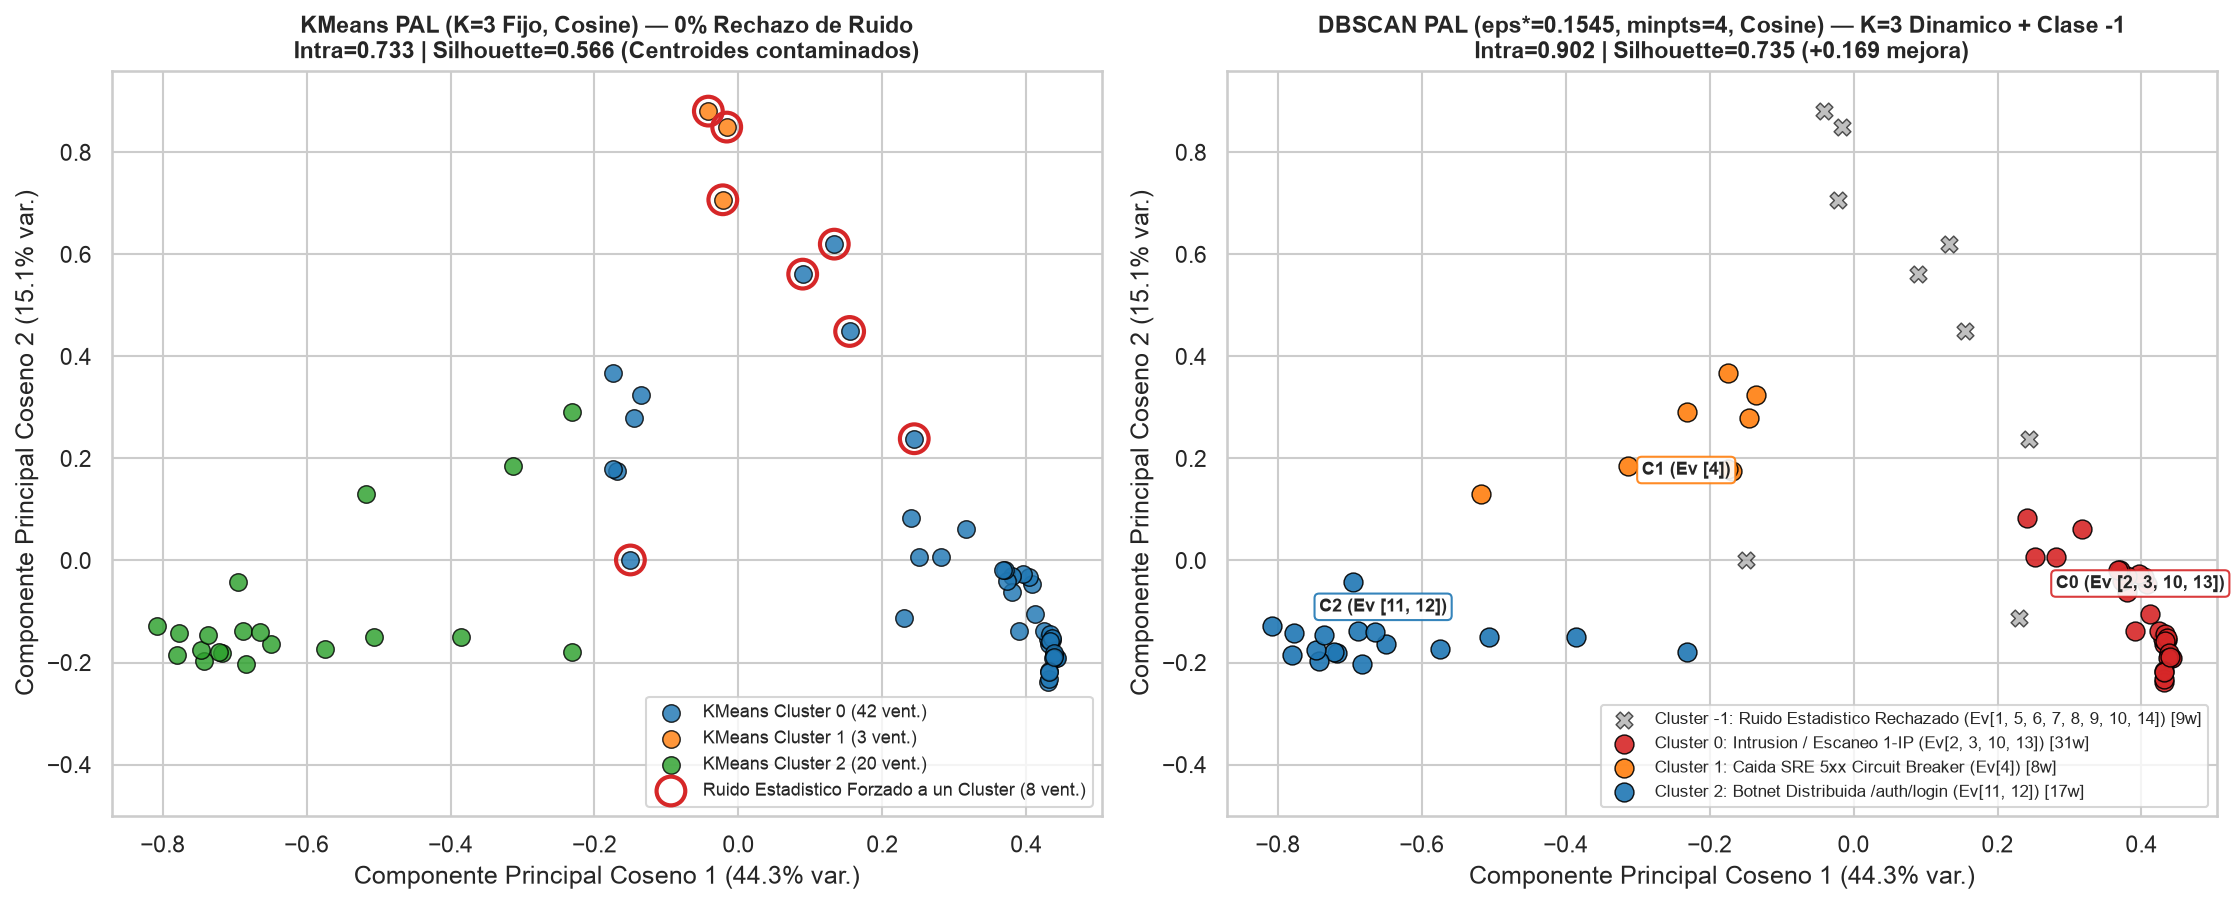

In [6]:
# --- FIGURA 2: PROYECCION PCA COSENO 2D COMPARANDO KMEANS (SIN RECHAZO DE RUIDO) VS DBSCAN PAL (SYSTEM) ---
U_centered = U_sys - U_sys.mean(axis=0, keepdims=True)
_, s_vals, vt_vecs = np.linalg.svd(U_centered, full_matrices=False)
coords_2d = U_centered @ vt_vecs[:2].T
var_exp = 100.0 * (s_vals[:2] ** 2) / np.sum(s_vals ** 2)

fig, axes = plt.subplots(1, 2, figsize=(15.2, 6.2))

# Izquierda: KMeans (K=3) fuerza las 9 ventanas de ruido dentro de los clusteres reales
paleta_km = {0: '#1f77b4', 1: '#ff7f0e', 2: '#2ca02c'}
for cid_k in sorted(an_sys_res['KMEANS_CID'].unique()):
    m_k = (an_sys_res['KMEANS_CID'] == cid_k).values
    axes[0].scatter(
        coords_2d[m_k, 0], coords_2d[m_k, 1],
        c=paleta_km.get(cid_k, '#333333'), s=70, alpha=0.82, edgecolors='black', linewidths=0.7,
        label=f'KMeans Cluster {cid_k} ({m_k.sum()} vent.)'
    )
# Resaltar con anillo rojo las ventanas que en realidad son eventos aislados de ruido (N_VENTANAS <= 2)
ruido_real_mask = an_sys_res['EVENTO_ID'].isin(eventos_system[eventos_system['N_VENTANAS'] <= 2]['EVENTO_ID']).values
axes[0].scatter(
    coords_2d[ruido_real_mask, 0], coords_2d[ruido_real_mask, 1],
    facecolors='none', edgecolors='#d62728', s=190, linewidths=2.0,
    label=f'Ruido Estadistico Forzado a un Cluster ({ruido_real_mask.sum()} vent.)'
)
axes[0].set_title(
    f"KMeans PAL (K=3 Fijo, Cosine) — 0% Rechazo de Ruido\n"
    f"Intra={comp_metricas.loc[1, 'INTRA_COS_SIM']:.3f} | Silhouette={comp_metricas.loc[1, 'SILHOUETTE_COS']:.3f} (Centroides contaminados)",
    fontsize=11, fontweight='bold'
)
axes[0].set_xlabel(f'Componente Principal Coseno 1 ({var_exp[0]:.1f}% var.)')
axes[0].set_ylabel(f'Componente Principal Coseno 2 ({var_exp[1]:.1f}% var.)')
axes[0].set_ylim(-0.50, 0.96)
axes[0].legend(loc='lower right', fontsize=8.5)

# Derecha: DBSCAN PAL descubre K=3 y aisla automaticamente CLUSTER_ID = -1
etiquetas_base_sys = {
    0: 'Cluster 0: Intrusion / Escaneo 1-IP',
    1: 'Cluster 1: Caida SRE 5xx Circuit Breaker',
    2: 'Cluster 2: Botnet Distribuida /auth/login',
    -1: 'Cluster -1: Ruido Estadistico Rechazado',
}
colores_db_sys = {0: '#d62728', 1: '#ff7f0e', 2: '#1f77b4', -1: '#9e9e9e'}

for cid_d in [-1, 0, 1, 2]:
    m_d = (an_sys_res['CLUSTER_ID'] == cid_d).values
    if not m_d.any():
        continue
    evs_d = sorted(an_sys_res.loc[m_d, 'EVENTO_ID'].unique().tolist())
    marker_d = 'X' if cid_d == -1 else 'o'
    size_d = 65 if cid_d == -1 else 82
    alpha_d = 0.65 if cid_d == -1 else 0.90
    axes[1].scatter(
        coords_2d[m_d, 0], coords_2d[m_d, 1],
        c=colores_db_sys[cid_d], marker=marker_d, s=size_d, alpha=alpha_d,
        edgecolors='black', linewidths=0.7,
        label=f"{etiquetas_base_sys[cid_d]} (Ev{evs_d}) [{m_d.sum()}w]"
    )
    if cid_d >= 0:
        cx, cy = coords_2d[m_d, 0].mean(), coords_2d[m_d, 1].mean()
        dy_off = 14 if cid_d != 1 else -18
        axes[1].annotate(
            f"C{cid_d} (Ev {evs_d})",
            (cx, cy), xytext=(0, dy_off), textcoords='offset points',
            ha='center', fontsize=8.8, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=colores_db_sys[cid_d], alpha=0.9)
        )

axes[1].set_title(
    f"DBSCAN PAL (eps*={eps_sys}, minpts=4, Cosine) — K=3 Dinamico + Clase -1\n"
    f"Intra={comp_metricas.loc[0, 'INTRA_COS_SIM']:.3f} | Silhouette={comp_metricas.loc[0, 'SILHOUETTE_COS']:.3f} (+{(comp_metricas.loc[0, 'SILHOUETTE_COS']-comp_metricas.loc[1, 'SILHOUETTE_COS']):.3f} mejora)",
    fontsize=11, fontweight='bold'
)
axes[1].set_xlabel(f'Componente Principal Coseno 1 ({var_exp[0]:.1f}% var.)')
axes[1].set_ylabel(f'Componente Principal Coseno 2 ({var_exp[1]:.1f}% var.)')
axes[1].set_ylim(-0.50, 0.96)
axes[1].legend(loc='lower right', fontsize=8.1)

fig.tight_layout()
plt.show()

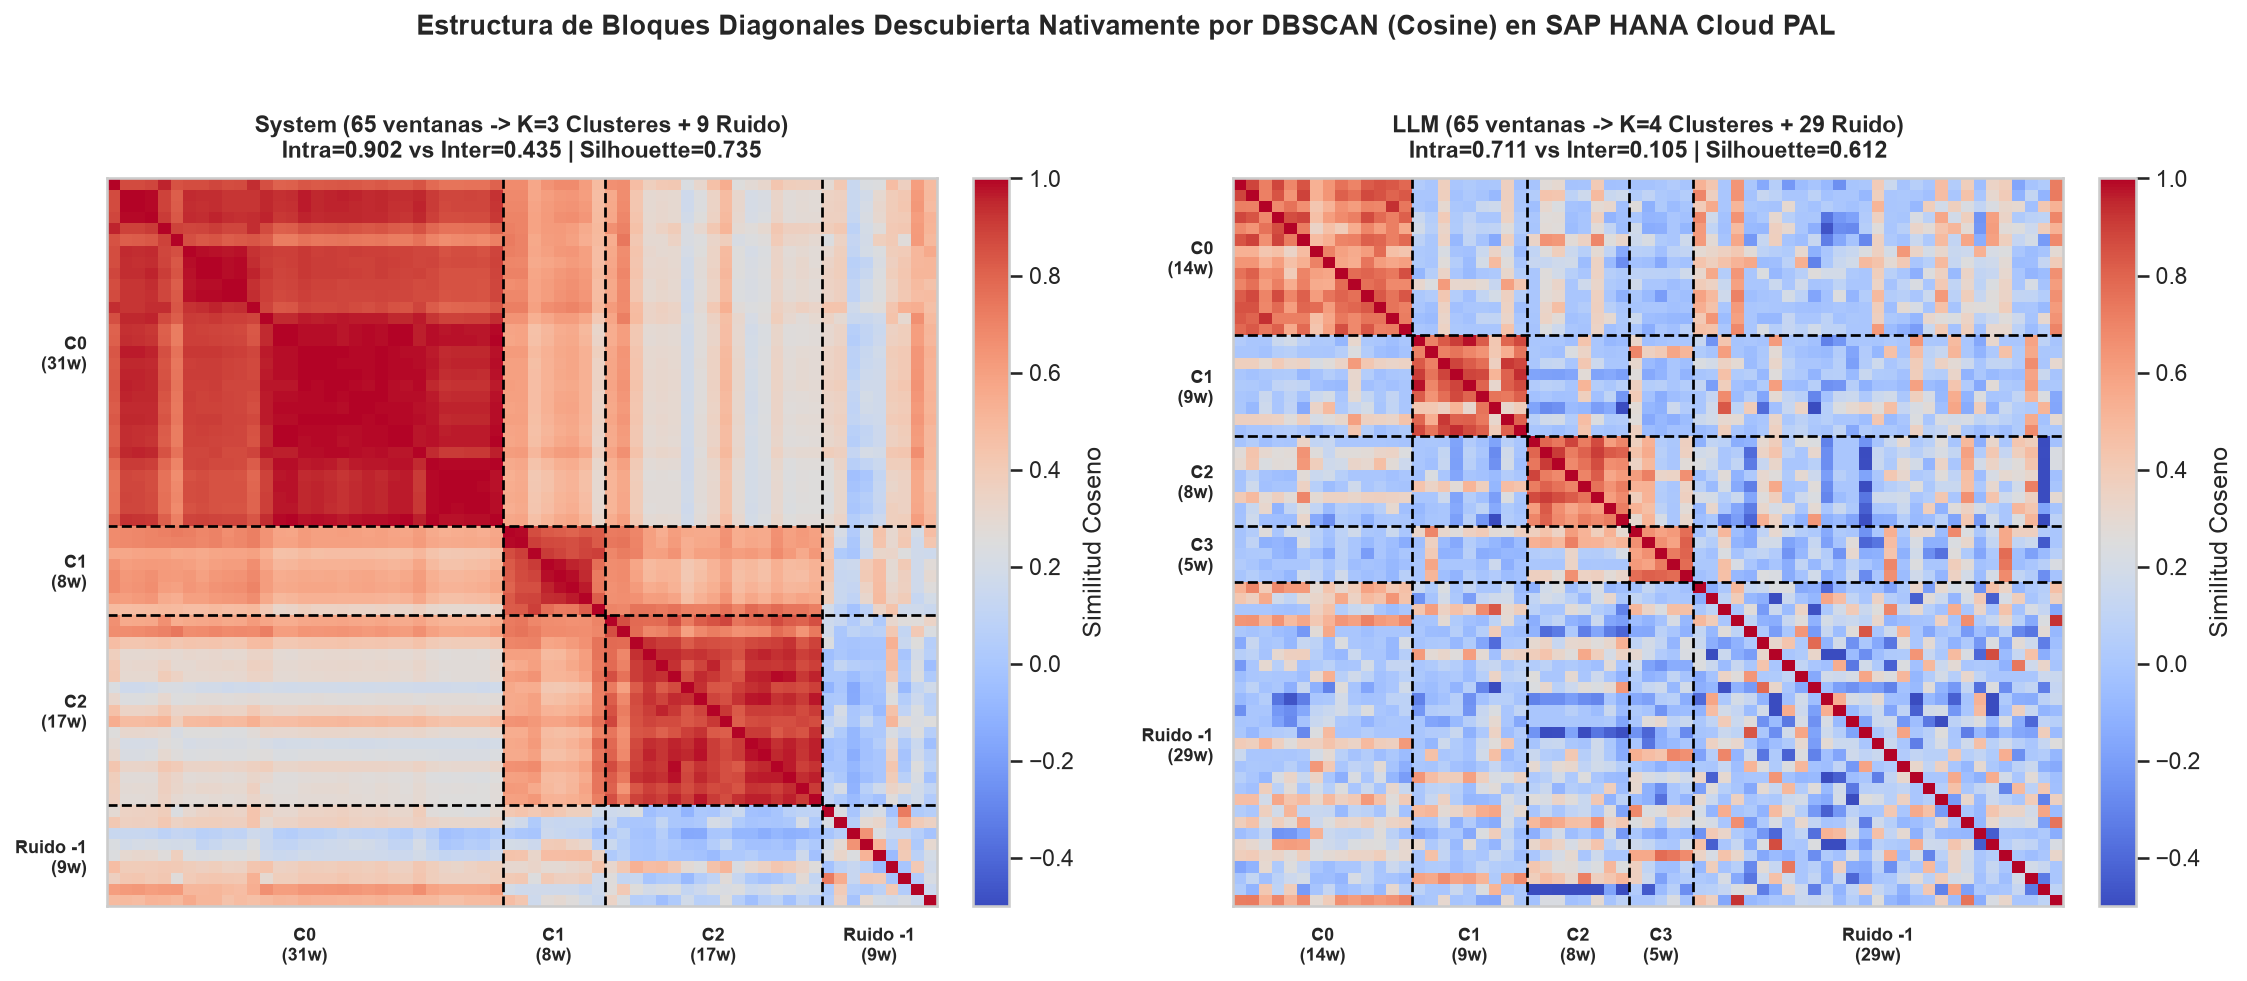

In [7]:
# --- FIGURA 3: MATRICES DE SIMILITUD COSENO ORDENADAS POR CLUSTER DBSCAN PAL (SYSTEM Y LLM) ---
fig, axes = plt.subplots(1, 2, figsize=(15.2, 6.4))

for ax, titulo, res_df, sim_mat, m_row in (
    (
        axes[0],
        f"System (65 ventanas -> K={int(comp_metricas.loc[0, 'K_CLUSTERS'])} Clusteres + {int(comp_metricas.loc[0, 'N_RUIDO'])} Ruido)",
        an_sys_res, cos_sim_sys, comp_metricas.iloc[0]
    ),
    (
        axes[1],
        f"LLM (65 ventanas -> K={int(comp_metricas.loc[2, 'K_CLUSTERS'])} Clusteres + {int(comp_metricas.loc[2, 'N_RUIDO'])} Ruido)",
        an_llm_res, cos_sim_llm, comp_metricas.iloc[2]
    ),
):
    # Ordenar primero los clusteres reales (0, 1, 2, ...) y al final el bloque de ruido (-1)
    sort_key = np.where(res_df['CLUSTER_ID'].values >= 0, res_df['CLUSTER_ID'].values, 999)
    orden_idx = np.lexsort((res_df['ANOM_ID'].values, sort_key))
    sim_ord = sim_mat[np.ix_(orden_idx, orden_idx)]
    cids_ord = res_df['CLUSTER_ID'].values[orden_idx]

    im = ax.imshow(sim_ord, cmap='coolwarm', vmin=-0.5, vmax=1.0, aspect='auto')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Similitud Coseno')

    # Dibujar fronteras exactas entre bloques de clusteres
    limites = []
    pos_ticks = []
    lbl_ticks = []
    unique_seq = []
    for v in cids_ord:
        if not unique_seq or unique_seq[-1] != v:
            unique_seq.append(v)
    cursor = 0
    for cid_val in unique_seq:
        cnt = int((cids_ord == cid_val).sum())
        pos_ticks.append(cursor + cnt / 2.0 - 0.5)
        lbl_ticks.append(f"C{cid_val}\n({cnt}w)" if cid_val >= 0 else f"Ruido -1\n({cnt}w)")
        cursor += cnt
        if cursor < len(cids_ord):
            ax.axhline(cursor - 0.5, color='black', lw=1.3, ls='--')
            ax.axvline(cursor - 0.5, color='black', lw=1.3, ls='--')

    ax.set_xticks(pos_ticks)
    ax.set_xticklabels(lbl_ticks, fontsize=8.8, fontweight='bold')
    ax.set_yticks(pos_ticks)
    ax.set_yticklabels(lbl_ticks, fontsize=8.8, fontweight='bold')
    ax.set_title(
        f"{titulo}\nIntra={m_row['INTRA_COS_SIM']:.3f} vs Inter={m_row['INTER_COS_SIM']:.3f} | Silhouette={m_row['SILHOUETTE_COS']:.3f}",
        fontsize=10.8, fontweight='bold', pad=10
    )
    ax.grid(False)

fig.suptitle('Estructura de Bloques Diagonales Descubierta Nativamente por DBSCAN (Cosine) en SAP HANA Cloud PAL', fontsize=12.8, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()

## 5. Prueba Experimental de $K$ Dinámico por Batch y Detección *Zero-Day* en *Streaming* (`DBSCAN.predict()`)

Para validar rigurosamente la recomendación del profesor sobre **$K$ dinámico**, sometemos el pipeline automatizado (`Kneedle` + `PAL DBSCAN`) a **dos pruebas operativas reales** sin modificar ni un solo hiperparámetro manual:

### Experimento 5A — Adaptación Automática de $K$ según las Amenazas Presentes en Cada Batch
Ejecutamos el motor de forma independiente sobre tres cortes temporales distintos:
1. **Batch Semana 0 (`01–07 Oct`):** Ocurrieron tres campañas monopolizadas por 1 IP (`Intrusión / Escaneo 1-IP`) y la caída operativa SRE `5xx` (`Circuit Breaker`), pero **ninguna Botnet**. El algoritmo debe descubrir por sí solo **$K = 2$**.
2. **Batch Semana 1 (`08–11 Oct`):** Ocurrieron las dos olas de *Botnet* contra `/auth/login` (`Eventos 11 y 12`) y el escaneo 1-IP a `/.git/config` (`Evento 13`), pero **ninguna caída SRE `5xx`**. El algoritmo debe descubrir por sí solo **$K = 2$** (con los dos arquetipos activos de esa semana).
3. **Batch Mes Completo (`01–11 Oct`):** Coexisten las tres familias. El algoritmo debe escalar automáticamente a **$K = 3$**.

### Experimento 5B — Detección de Ataques *Zero-Day* en Tiempo Real con `DBSCAN.predict()` en HANA PAL
Entrenamos `DBSCAN(save_model=True)` **únicamente con los datos históricos de la Semana 0** ($K = 2$) e invocamos `db_w0.predict()` en SAP HANA PAL cuando llegan las ventanas anómalas de la **Semana 1**:
- Si un evento nuevo pertenece a una familia ya conocida (`Evento 13`, escaneo 1-IP), debe caer dentro del radio $\varepsilon^*_{W0}$ (`PRED_CLUSTER_ID >= 0`, `CORE_DISTANCE` cercana a $0$).
- Si llega una ventana aislada de cola estadística (`Evento 14`, 1 ventana), recibe `PRED_CLUSTER_ID = -1` y se descarta por baja persistencia (`N_VENTANAS < minpts`).
- Si irrumpe una **campaña persistente de un arquetipo nunca visto en la Semana 0** (`Eventos 11 y 12`, *Botnet* distribuida de 270 IPs con `8` y `9` ventanas consecutivas), recibe **`PRED_CLUSTER_ID = -1` con `N_VENTANAS >= minpts`**, disparando automáticamente una alerta de **Amenaza *Zero-Day* / Nuevo Arquetipo** y re-entrenando el catálogo de clústeres.

[K-DINAMICO] ADAPTACION AUTOMATICA DE K POR BATCH EN SAP HANA PAL DBSCAN (CERO AJUSTE MANUAL):


,ESCENARIO_BATCH,VENTANAS_IF,EPS_AUTO_KNEEDLE,K_DINAMICO_DESCUBIERTO,VENTANAS_RUIDO_(-1),SILHOUETTE_COS,ARQUETIPOS_ACTIVOS_DESCUBIERTOS
0,Semana 0 (01-07 Oct),41,0.1859,2,8,0.7730,"C0: Intrusion / Escaneo 1-IP (Ev[2, 3, 10]) | C1: Caida Operativa 5xx (Ev[4])"
1,Semana 1 (08-11 Oct),24,0.1424,2,2,0.8804,"C0: Botnet Distribuida Auth (Ev[11, 12]) | C1: Intrusion / Escaneo 1-IP (Ev[13])"
2,Mes Completo (01-11 Oct),65,0.1545,3,9,0.7349,"C0: Intrusion / Escaneo 1-IP (Ev[2, 3, 10, 13]) | C1: Caida Operativa 5xx (Ev[4]) | C2: Botnet Distribuida Auth (Ev[11, 12])"



[ZERO-DAY] INFERENCIA STREAMING CON DBSCAN.PREDICT() EN HANA PAL (MODELO ENTRENADO SOLO EN SEMANA 0):


,EVENTO_ID_W1,INICIO_UTC,N_VENTANAS,SCORE_MAX,PRED_CLUSTER_W0,DIST_MIN_NUCLEO_W0,DIST_MEDIA_NUCLEO_W0,UMBRAL_EPS_W0,VEREDICTO_STREAMING_PAL
0,11,2026-10-09 09:17:30,8,0.6568,-1,0.2402,0.2613,0.1859,[ALERTA ZERO-DAY] Arquetipo Persistente NO Visto en Semana 0 -> Crear Nuevo Cluster
1,12,2026-10-09 10:00:00,9,0.6175,-1,0.2200,0.2572,0.1859,[ALERTA ZERO-DAY] Arquetipo Persistente NO Visto en Semana 0 -> Crear Nuevo Cluster
2,13,2026-10-10 02:40:00,6,0.8044,0,0.0049,0.0183,0.1859,[CONOCIDO] Coincide con Cluster 0 de Semana 0 (1-IP Intrusion/Scan)
3,14,2026-10-10 21:37:30,1,0.5444,-1,0.4433,0.4433,0.1859,[RUIDO] Anomalia Puntual Aislada (< minpts) -> Descartar


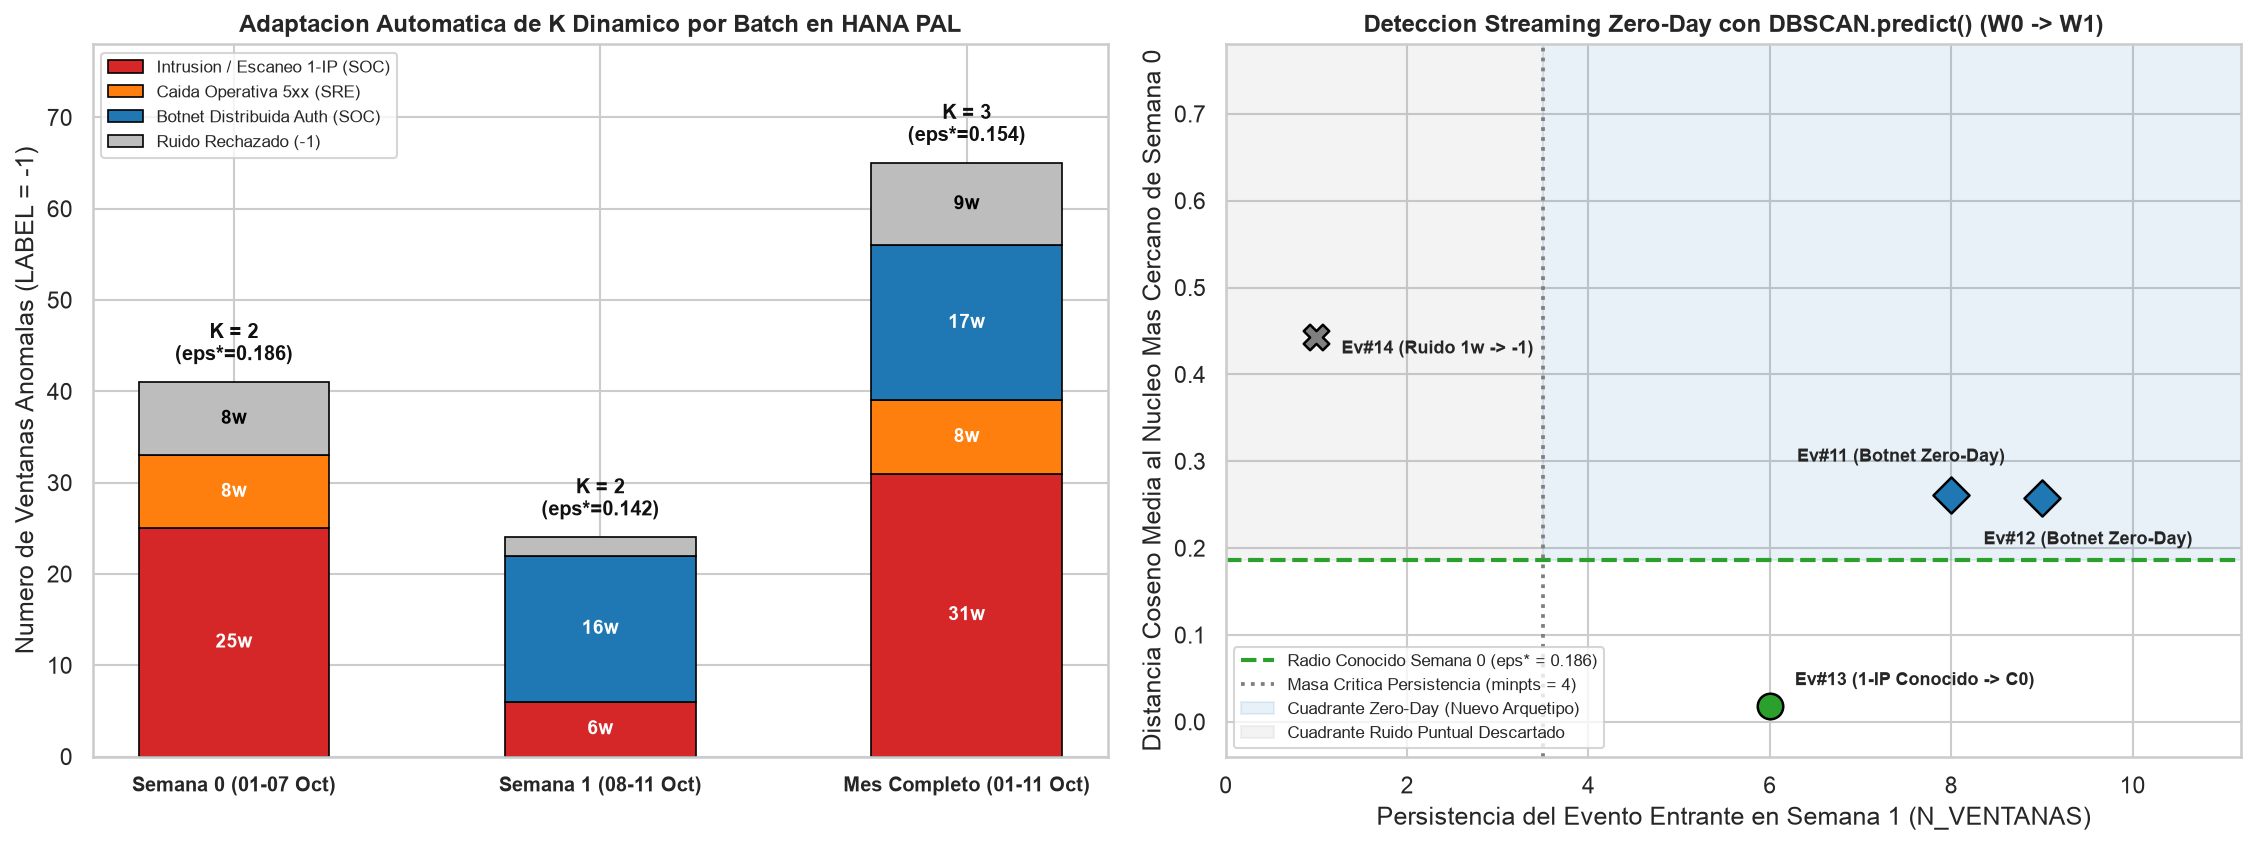

In [8]:
# --- EXPERIMENTO 5A: K DINAMICO AUTOMATICO POR BATCH (SEMANA 0 VS SEMANA 1 VS MES COMPLETO) ---
escenarios_batch = [
    ('Semana 0 (01-07 Oct)', an_sys['WEEK'] == 0),
    ('Semana 1 (08-11 Oct)', an_sys['WEEK'] == 1),
    ('Mes Completo (01-11 Oct)', an_sys['WEEK'] >= 0),
]

batch_rows = []
composicion_batches = {}
modelos_batch = {}

for nombre_b, mask_b in escenarios_batch:
    sub_an = an_sys[mask_b].copy().reset_index(drop=True)
    sub_z = Z_clean_sys[mask_b].copy().reset_index(drop=True)
    sub_an['ANOM_ID'] = np.arange(1, len(sub_an) + 1, dtype=int)

    eps_b, knee_b, _, _, _ = calibrar_eps_kneedle(sub_z, MINPTS_DEFAULT)
    t_name = f"#TMP_BATCH_{len(batch_rows)}"
    mod_b, hana_b, res_b = ejecutar_dbscan_pal_completo(
        conn, t_name, sub_an, sub_z, FEATURES_SYSTEM, MINPTS_DEFAULT, eps_b
    )
    met_b = metricas_clustering_coseno(sub_z, res_b['CLUSTER_ID'].values)

    # Identificar semanticamente que arquetipos descubrio en ese batch
    conteo_arq = {'Intrusion / Escaneo 1-IP (SOC)': 0, 'Botnet Distribuida Auth (SOC)': 0,
                  'Caida Operativa 5xx (SRE)': 0, 'Ruido Rechazado (-1)': int((res_b['CLUSTER_ID'] == -1).sum())}
    desc_clusters = []
    for cid_b in sorted(set(res_b['CLUSTER_ID']) - {-1}):
        g_b = res_b[res_b['CLUSTER_ID'] == cid_b]
        evs_b = sorted(g_b['EVENTO_ID'].unique().tolist())
        if g_b['IP_TOP_SHARE'].mean() > 0.10:
            tipo_b = 'Intrusion / Escaneo 1-IP (SOC)'
        elif sub_z.loc[g_b.index, 'ERROR_RATE_500'].mean() > 1.0:
            tipo_b = 'Caida Operativa 5xx (SRE)'
        else:
            tipo_b = 'Botnet Distribuida Auth (SOC)'
        conteo_arq[tipo_b] += len(g_b)
        desc_clusters.append(f"C{cid_b}: {tipo_b.split(' (')[0]} (Ev{evs_b})")

    composicion_batches[nombre_b] = conteo_arq
    modelos_batch[nombre_b] = (mod_b, hana_b, eps_b, sub_an, sub_z)
    batch_rows.append({
        'ESCENARIO_BATCH': nombre_b,
        'VENTANAS_IF': len(sub_an),
        'EPS_AUTO_KNEEDLE': eps_b,
        'K_DINAMICO_DESCUBIERTO': met_b['K_CLUSTERS'],
        'VENTANAS_RUIDO_(-1)': met_b['N_RUIDO'],
        'SILHOUETTE_COS': met_b['SILHOUETTE_COS'],
        'ARQUETIPOS_ACTIVOS_DESCUBIERTOS': ' | '.join(desc_clusters),
    })

df_k_dinamico = pd.DataFrame(batch_rows)
print("[K-DINAMICO] ADAPTACION AUTOMATICA DE K POR BATCH EN SAP HANA PAL DBSCAN (CERO AJUSTE MANUAL):")
display(df_k_dinamico)

# --- EXPERIMENTO 5B: STREAMING / DETECCION ZERO-DAY CON DBSCAN.PREDICT() (SEMANA 0 -> SEMANA 1) ---
mod_w0, hana_w0, eps_w0, _, _ = modelos_batch['Semana 0 (01-07 Oct)']
_, hana_w1, _, sub_an_w1, _ = modelos_batch['Semana 1 (08-11 Oct)']

pred_stream_w1 = mod_w0.predict(data=hana_w1, key='ANOM_ID', features=FEATURES_SYSTEM).collect().sort_values('ANOM_ID')
df_stream_w1 = sub_an_w1.copy()
df_stream_w1['PRED_CID_W0'] = pred_stream_w1['CLUSTER_ID'].values.astype(int)
df_stream_w1['DIST_AL_NUCLEO_W0'] = pred_stream_w1['DISTANCE'].values.astype(float)

ev_stream_rows = []
for eid_w1, grp_w1 in df_stream_w1.groupby('EVENTO_ID'):
    n_w = len(grp_w1)
    pred_dom = int(grp_w1['PRED_CID_W0'].value_counts().index[0])
    min_d = float(grp_w1['DIST_AL_NUCLEO_W0'].min())
    mean_d = float(grp_w1['DIST_AL_NUCLEO_W0'].mean())
    if pred_dom >= 0:
        veredicto = f"[CONOCIDO] Coincide con Cluster {pred_dom} de Semana 0 (1-IP Intrusion/Scan)"
    elif n_w >= MINPTS_DEFAULT:
        veredicto = "[ALERTA ZERO-DAY] Arquetipo Persistente NO Visto en Semana 0 -> Crear Nuevo Cluster"
    else:
        veredicto = "[RUIDO] Anomalia Puntual Aislada (< minpts) -> Descartar"
    ev_stream_rows.append({
        'EVENTO_ID_W1': int(eid_w1),
        'INICIO_UTC': grp_w1['WINDOW_START'].min(),
        'N_VENTANAS': n_w,
        'SCORE_MAX': round(float(grp_w1['SCORE'].max()), 4),
        'PRED_CLUSTER_W0': pred_dom,
        'DIST_MIN_NUCLEO_W0': round(min_d, 4),
        'DIST_MEDIA_NUCLEO_W0': round(mean_d, 4),
        'UMBRAL_EPS_W0': eps_w0,
        'VEREDICTO_STREAMING_PAL': veredicto,
    })

# Limpiar tablas temporales de los batches de prueba
for idx_b in range(len(escenarios_batch)):
    ventanas.drop_temp(conn, f"#TMP_BATCH_{idx_b}")

df_zeroday_w1 = pd.DataFrame(ev_stream_rows)
print("\n[ZERO-DAY] INFERENCIA STREAMING CON DBSCAN.PREDICT() EN HANA PAL (MODELO ENTRENADO SOLO EN SEMANA 0):")
display(df_zeroday_w1)

# --- FIGURA 4: K DINAMICO POR BATCH Y CUADRANTES DE DETECCION ZERO-DAY EN STREAMING ---
fig, axes = plt.subplots(1, 2, figsize=(15.2, 5.8))

# Panel 1: Barras apiladas de composicion y K dinamico por batch
nombres_b_list = [r['ESCENARIO_BATCH'] for r in batch_rows]
cats_plot = [
    ('Intrusion / Escaneo 1-IP (SOC)', '#d62728'),
    ('Caida Operativa 5xx (SRE)', '#ff7f0e'),
    ('Botnet Distribuida Auth (SOC)', '#1f77b4'),
    ('Ruido Rechazado (-1)', '#bdbdbd'),
]
bottom_vals = np.zeros(len(nombres_b_list))
x_pos = np.arange(len(nombres_b_list))

for cat_label, col_hex in cats_plot:
    vals_c = np.array([composicion_batches[nb][cat_label] for nb in nombres_b_list], dtype=float)
    axes[0].bar(x_pos, vals_c, bottom=bottom_vals, width=0.52, color=col_hex, edgecolor='black', linewidth=0.8, label=cat_label)
    for idx_x, v_item in enumerate(vals_c):
        if v_item >= 4:
            axes[0].text(idx_x, bottom_vals[idx_x] + v_item / 2.0, f"{int(v_item)}w", ha='center', va='center', fontsize=9, fontweight='bold', color='white' if col_hex != '#bdbdbd' else 'black')
    bottom_vals += vals_c

for idx_x, r_b in enumerate(batch_rows):
    axes[0].text(
        idx_x, bottom_vals[idx_x] + 1.8,
        f"K = {r_b['K_DINAMICO_DESCUBIERTO']}\n(eps*={r_b['EPS_AUTO_KNEEDLE']:.3f})",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#111111'
    )

axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(nombres_b_list, fontsize=9.5, fontweight='bold')
axes[0].set_ylim(0, 78)
axes[0].set_ylabel('Numero de Ventanas Anomalas (LABEL = -1)')
axes[0].set_title('Adaptacion Automatica de K Dinamico por Batch en HANA PAL', fontsize=11.3, fontweight='bold')
axes[0].legend(loc='upper left', fontsize=8.3)

# Panel 2: Mapa de Cuadrantes Zero-Day (Distancia al Nucleo W0 vs Persistencia N_VENTANAS)
axes[1].axhline(eps_w0, color='#2ca02c', ls='--', lw=2, label=f'Radio Conocido Semana 0 (eps* = {eps_w0:.3f})')
axes[1].axvline(MINPTS_DEFAULT - 0.5, color='#7f7f7f', ls=':', lw=1.8, label=f'Masa Critica Persistencia (minpts = {MINPTS_DEFAULT})')
axes[1].fill_between([MINPTS_DEFAULT - 0.5, 11.5], eps_w0, 0.80, color='#1f77b4', alpha=0.10, label='Cuadrante Zero-Day (Nuevo Arquetipo)')
axes[1].fill_between([0, MINPTS_DEFAULT - 0.5], eps_w0, 0.80, color='#9e9e9e', alpha=0.12, label='Cuadrante Ruido Puntual Descartado')

offsets_zd = {11: (-74, 16), 12: (-28, -22), 13: (12, 10), 14: (12, -8)}
for _, r_z in df_zeroday_w1.iterrows():
    eid_z = int(r_z['EVENTO_ID_W1'])
    if r_z['PRED_CLUSTER_W0'] >= 0:
        col_z, mk_z = '#2ca02c', 'o'
    elif r_z['N_VENTANAS'] >= MINPTS_DEFAULT:
        col_z, mk_z = '#1f77b4', 'D'
    else:
        col_z, mk_z = '#7f7f7f', 'X'
    axes[1].scatter(r_z['N_VENTANAS'], r_z['DIST_MEDIA_NUCLEO_W0'], s=150, c=col_z, marker=mk_z, edgecolors='black', linewidths=1.2, zorder=5)
    dx_z, dy_z = offsets_zd.get(eid_z, (10, 8))
    etiqueta_z = (
        f"Ev#{eid_z} (Botnet Zero-Day)" if eid_z in (11, 12)
        else (f"Ev#{eid_z} (1-IP Conocido -> C0)" if eid_z == 13 else f"Ev#{eid_z} (Ruido 1w -> -1)")
    )
    axes[1].annotate(etiqueta_z, (r_z['N_VENTANAS'], r_z['DIST_MEDIA_NUCLEO_W0']), xytext=(dx_z, dy_z), textcoords='offset points', fontsize=8.8, fontweight='bold')

axes[1].set_xlim(0, 11.2)
axes[1].set_ylim(-0.04, 0.78)
axes[1].set_xlabel('Persistencia del Evento Entrante en Semana 1 (N_VENTANAS)')
axes[1].set_ylabel('Distancia Coseno Media al Nucleo Mas Cercano de Semana 0')
axes[1].set_title('Deteccion Streaming Zero-Day con DBSCAN.predict() (W0 -> W1)', fontsize=11.3, fontweight='bold')
axes[1].legend(loc='lower left', fontsize=8.0)

fig.tight_layout()
plt.show()

## 6. Autopsia Forense SQL en Vivo sobre `LOGS_2026_10` por Clúster de Densidad (System y LLM)

Finalmente, cerramos el ciclo conectando cada `CLUSTER_ID` descubierto por **`DBSCAN` en SAP HANA Cloud PAL** con los registros crudos de `LOGS_2026_10` mediante consultas SQL directas. Esto demuestra que los clústeres de densidad **no son artefactos matemáticos**, sino familias operativas y de ciberseguridad con correspondencia forense 1 a 1 tanto en **System** ($K = 3$ clústeres + clase `-1`) como en **LLM** ($K = 4$ clústeres + clase `-1`, rescatando las campañas que `Z_UMBRAL = 5` perdía por completo).

In [9]:
def auditar_cluster_system_sql(conn, cid, sub_win):
    rangos = []
    for _, w_row in sub_win.iterrows():
        ini_s = w_row['WINDOW_START'].strftime('%Y-%m-%dT%H:%M:%S')
        fin_s = (w_row['WINDOW_START'] + pd.Timedelta(minutes=5)).strftime('%Y-%m-%dT%H:%M:%S')
        rangos.append(f'("TIMESTAMP" >= \'{ini_s}\' AND "TIMESTAMP" < \'{fin_s}\')')
    where_sql = f'"_INDEX" LIKE \'sap-logs%\' AND ({ " OR ".join(rangos) })'

    q_agg = conn.sql(f'''
        SELECT COUNT(*) AS LOGS_TOT,
               COUNT(DISTINCT "CLIENT_IP") AS IPS_UNICAS,
               SUM(CASE WHEN UPPER("SAP_FUNCTION_LOG_TYPE") = 'SECURITY' THEN 1 ELSE 0 END) AS SEC_LOGS,
               SUM(CASE WHEN "HTTP_STATUS_CODE" BETWEEN '500' AND '599' THEN 1 ELSE 0 END) AS HTTP_5XX
        FROM "{TABLA_OCTUBRE}" WHERE {where_sql}
    ''').collect().iloc[0]

    q_ip = conn.sql(f'''
        SELECT "CLIENT_IP", COUNT(*) AS C FROM "{TABLA_OCTUBRE}"
        WHERE {where_sql} AND "CLIENT_IP" IS NOT NULL
        GROUP BY "CLIENT_IP" ORDER BY C DESC LIMIT 2
    ''').collect()

    q_app = conn.sql(f'''
        SELECT "SAP_FUNCTION_APPLICATION", COUNT(*) AS C FROM "{TABLA_OCTUBRE}"
        WHERE {where_sql} AND (UPPER("SAP_FUNCTION_LOG_TYPE") IN ('SECURITY', 'ERROR') OR "HTTP_STATUS_CODE" <> '200')
        GROUP BY "SAP_FUNCTION_APPLICATION" ORDER BY C DESC LIMIT 2
    ''').collect()

    q_path = conn.sql(f'''
        SELECT "HEATHERS_REQUEST_PATH", COUNT(*) AS C FROM "{TABLA_OCTUBRE}"
        WHERE {where_sql} AND (UPPER("SAP_FUNCTION_LOG_TYPE") IN ('SECURITY', 'ERROR') OR "HTTP_STATUS_CODE" <> '200')
        GROUP BY "HEATHERS_REQUEST_PATH" ORDER BY C DESC LIMIT 2
    ''').collect()

    z_err500 = float(Z_clean_sys.loc[sub_win.index, 'ERROR_RATE_500'].mean())
    if sub_win['IP_TOP_SHARE'].mean() > 0.10:
        etiqueta = '[SOC] Intrusion / Reconocimiento / Escaneo Monopolizado (1-IP)'
        cond_msg_sys = 'UPPER("SAP_FUNCTION_LOG_TYPE") = \'SECURITY\''
    elif z_err500 > 1.0:
        etiqueta = '[SRE] Degradacion Operativa Critica (Tormenta HTTP 5xx / Circuit Breaker)'
        cond_msg_sys = '(UPPER("SAP_FUNCTION_LOG_TYPE") = \'ERROR\' OR "HTTP_STATUS_CODE" BETWEEN \'500\' AND \'599\')'
    else:
        etiqueta = '[SOC] Ataque Distribuido Botnet (Credential Stuffing /auth/login)'
        cond_msg_sys = 'UPPER("SAP_FUNCTION_LOG_TYPE") = \'SECURITY\''

    q_msg = conn.sql(f'''
        SELECT "SAP_FUNCTION_MESSAGE", COUNT(*) AS C FROM "{TABLA_OCTUBRE}"
        WHERE {where_sql} AND {cond_msg_sys}
        GROUP BY "SAP_FUNCTION_MESSAGE" ORDER BY C DESC LIMIT 1
    ''').collect()
    if q_msg.empty:
        q_msg = conn.sql(f'''
            SELECT "SAP_FUNCTION_MESSAGE", COUNT(*) AS C FROM "{TABLA_OCTUBRE}"
            WHERE {where_sql} AND UPPER("SAP_FUNCTION_LOG_TYPE") IN ('SECURITY', 'ERROR')
            GROUP BY "SAP_FUNCTION_MESSAGE" ORDER BY C DESC LIMIT 1
        ''').collect()

    top_ip_txt = ', '.join([f"{r['CLIENT_IP']} ({100.0*r['C']/max(q_agg['LOGS_TOT'],1):.1f}%)" for _, r in q_ip.iterrows()])
    apps_txt = ', '.join(q_app['SAP_FUNCTION_APPLICATION'].dropna().tolist())
    paths_txt = ', '.join(q_path['HEATHERS_REQUEST_PATH'].dropna().tolist())
    msg_txt = q_msg.iloc[0]['SAP_FUNCTION_MESSAGE'][:82] if not q_msg.empty else 'N/A'

    return {
        'CLUSTER_ID': int(cid),
        'DIAGNOSTICO_CLUSTER': etiqueta,
        'N_VENTANAS': len(sub_win),
        'EVENTOS_AGRUPADOS': sorted(sub_win['EVENTO_ID'].unique().tolist()),
        'SCORE_MAX': round(float(sub_win['SCORE'].max()), 4),
        'IPS_UNICAS_SQL': int(q_agg['IPS_UNICAS']),
        'ALERTAS_SECURITY_SQL': int(q_agg['SEC_LOGS'] or 0),
        'ERRORES_5XX_SQL': int(q_agg['HTTP_5XX'] or 0),
        'ACTORES_TOP_IP': top_ip_txt,
        'APPS_SAP_AFECTADAS': apps_txt,
        'ENDPOINTS_CRITICOS': paths_txt,
        'MENSAJE_EVIDENCIA_TOP': msg_txt,
    }

def auditar_cluster_llm_sql(conn, cid, sub_win):
    rangos = []
    for _, w_row in sub_win.iterrows():
        ini_s = w_row['WINDOW_START'].strftime('%Y-%m-%dT%H:%M:%S')
        fin_s = (w_row['WINDOW_START'] + pd.Timedelta(minutes=5)).strftime('%Y-%m-%dT%H:%M:%S')
        rangos.append(f'("TIMESTAMP" >= \'{ini_s}\' AND "TIMESTAMP" < \'{fin_s}\')')
    where_sql = f'"_INDEX" LIKE \'llm-logs%\' AND ({ " OR ".join(rangos) })'

    feat_dom = sub_win['TOP_FEATURE_Z'].value_counts().index[0]
    if feat_dom in ventanas.LLM_MESSAGE_THEMES:
        cond_tema = '(' + ' OR '.join(
            f'UPPER(COALESCE("SAP_FUNCTION_MESSAGE", \'\')) LIKE \'{pat}\''
            for pat in ventanas.LLM_MESSAGE_THEMES[feat_dom]
        ) + ')'
    elif feat_dom in ('LLM_TIMEOUT_RATE', 'AVG_RESPONSE_TIME_MS'):
        cond_tema = 'UPPER("LLM_STATUS") = \'TIMEOUT\''
    else:
        cond_tema = 'UPPER("LLM_STATUS") IN (\'ERROR\', \'TIMEOUT\')'

    q_agg = conn.sql(f'''
        SELECT COUNT(*) AS LOGS_TOT,
               SUM(CASE WHEN UPPER("LLM_STATUS") = 'ERROR' THEN 1 ELSE 0 END) AS ERR_TOT,
               SUM(CASE WHEN UPPER("LLM_STATUS") = 'TIMEOUT' THEN 1 ELSE 0 END) AS TMO_TOT
        FROM "{TABLA_OCTUBRE}" WHERE {where_sql}
    ''').collect().iloc[0]

    q_mod = conn.sql(f'''
        SELECT "LLM_PROVIDER", "LLM_MODEL_ID", COUNT(*) AS C FROM "{TABLA_OCTUBRE}"
        WHERE {where_sql} AND {cond_tema}
        GROUP BY "LLM_PROVIDER", "LLM_MODEL_ID" ORDER BY C DESC LIMIT 2
    ''').collect()

    q_msg = conn.sql(f'''
        SELECT "SAP_FUNCTION_MESSAGE", COUNT(*) AS C FROM "{TABLA_OCTUBRE}"
        WHERE {where_sql} AND {cond_tema}
        GROUP BY "SAP_FUNCTION_MESSAGE" ORDER BY C DESC LIMIT 1
    ''').collect()

    mapa_diag_llm = {
        'DUPLICATE_REQUEST_COUNT': '[SOC/App] Abuso / Replay de Peticiones Identicas (Duplicate Request)',
        'INJECTION_COUNT': '[SOC] Campana de Sondeo Prompt Injection y Evasion Adversarial',
        'LLM_TIMEOUT_RATE': '[SRE] Degradacion de Proveedor LLM (Rafagas de Timeouts 30s y Latencia)',
        'AVG_RESPONSE_TIME_MS': '[SRE] Degradacion de Proveedor LLM (Rafagas de Timeouts 30s y Latencia)',
        'SAFETY_POLICY_COUNT': '[SOC] Violaciones Recurrentes de Guardrails / Content Safety Policy',
    }
    modelos_txt = ', '.join([f"{r['LLM_PROVIDER']}/{r['LLM_MODEL_ID']}" for _, r in q_mod.iterrows()])
    msg_txt = q_msg.iloc[0]['SAP_FUNCTION_MESSAGE'][:88] if not q_msg.empty else 'N/A'

    return {
        'CLUSTER_ID': int(cid),
        'DIAGNOSTICO_CLUSTER': mapa_diag_llm.get(feat_dom, f'[Anomalia LLM] Dominada por {feat_dom}'),
        'N_VENTANAS': len(sub_win),
        'N_EVENTOS_DISTINTOS': int(sub_win['EVENTO_ID'].nunique()),
        'SCORE_MAX': round(float(sub_win['SCORE'].max()), 4),
        'FEATURE_DOMINANTE': feat_dom,
        'ERRORES_LLM_SQL': int(q_agg['ERR_TOT'] or 0),
        'TIMEOUTS_LLM_SQL': int(q_agg['TMO_TOT'] or 0),
        'MODELOS_AFECTADOS': modelos_txt,
        'MENSAJE_EVIDENCIA_TOP': msg_txt,
    }

catalogo_sys_sql = pd.DataFrame([
    auditar_cluster_system_sql(conn, cid, an_sys_res[an_sys_res['CLUSTER_ID'] == cid])
    for cid in sorted(set(an_sys_res['CLUSTER_ID']) - {-1})
])
catalogo_llm_sql = pd.DataFrame([
    auditar_cluster_llm_sql(conn, cid, an_llm_res[an_llm_res['CLUSTER_ID'] == cid])
    for cid in sorted(set(an_llm_res['CLUSTER_ID']) - {-1})
])

print("[FORENSE SYSTEM] CATALOGO DE CLUSTERES DE DENSIDAD DBSCAN PAL VALIDADOS CONTRA LOGS_2026_10:")
display(catalogo_sys_sql)

print("\n[FORENSE LLM] CATALOGO DE CLUSTERES DE DENSIDAD DBSCAN PAL VALIDADOS CONTRA LOGS_2026_10:")
display(catalogo_llm_sql)

[FORENSE SYSTEM] CATALOGO DE CLUSTERES DE DENSIDAD DBSCAN PAL VALIDADOS CONTRA LOGS_2026_10:


,CLUSTER_ID,DIAGNOSTICO_CLUSTER,N_VENTANAS,EVENTOS_AGRUPADOS,SCORE_MAX,IPS_UNICAS_SQL,ALERTAS_SECURITY_SQL,ERRORES_5XX_SQL,ACTORES_TOP_IP,APPS_SAP_AFECTADAS,ENDPOINTS_CRITICOS,MENSAJE_EVIDENCIA_TOP
0,0,[SOC] Intrusion / Reconocimiento / Escaneo Monopolizado (1-IP),31,"[2, 3, 10, 13]",0.8084,108,1567,914,"141.55.188.153 (7.2%), 192.168.250.11 (6.9%)","sap-s4hana-finance, sap-ariba","/api/sap-s4hana-finance/auth/login, /sap/bc/rest/rfc/invoke",Unauthorized system access attempt detected on sap-s4hana-finance via BAPI — reque
1,1,[SRE] Degradacion Operativa Critica (Tormenta HTTP 5xx / Circuit Breaker),8,[4],0.7042,202,102,432,"63.205.226.109 (1.2%), 192.168.1.130 (1.1%)","sap-analytics-cloud, sap-ariba","/sap/bc/rest/rest/invoke, /api/v1/sap-analytics-cloud/execute",Circuit breaker OPEN for sap-analytics-cloud after 5 failures.
2,2,[SOC] Ataque Distribuido Botnet (Credential Stuffing /auth/login),17,"[11, 12]",0.6568,163,331,653,"78.16.122.86 (1.2%), 106.197.210.159 (1.2%)","sap-ariba, sap-intelligent-rpa","/api/sap-ariba/auth/login, /sap/bc/rest/odata/invoke",Two consecutive failed logins on sap-ariba — within acceptable threshold.



[FORENSE LLM] CATALOGO DE CLUSTERES DE DENSIDAD DBSCAN PAL VALIDADOS CONTRA LOGS_2026_10:


,CLUSTER_ID,DIAGNOSTICO_CLUSTER,N_VENTANAS,N_EVENTOS_DISTINTOS,SCORE_MAX,FEATURE_DOMINANTE,ERRORES_LLM_SQL,TIMEOUTS_LLM_SQL,MODELOS_AFECTADOS,MENSAJE_EVIDENCIA_TOP
0,0,[SOC/App] Abuso / Replay de Peticiones Identicas (Duplicate Request),14,11,0.5596,DUPLICATE_REQUEST_COUNT,1269,630,"OpenAI/gpt-4o, OpenAI/gpt-4","LLM ERROR: Identical request ID submitted more than once. (model=chatgpt-sol, app=sap-co"
1,1,[SOC] Campana de Sondeo Prompt Injection y Evasion Adversarial,9,9,0.5431,INJECTION_COUNT,939,423,"Google/gemini-2.0-flash, Google/gemini-1.5-flash","LLM ERROR: Prompt injection detected and blocked. (model=claude-opus-5.5, app=sap-intell"
2,2,[SRE] Degradacion de Proveedor LLM (Rafagas de Timeouts 30s y Latencia),8,7,0.5561,LLM_TIMEOUT_RATE,675,510,"Google/gemini-1.5-flash, Anthropic/claude-sonnet-4.6","LLM TIMEOUT: Request timed out after 30 s. (model=gpt-4o-mini, app=sap-ariba)"
3,3,[SOC] Violaciones Recurrentes de Guardrails / Content Safety Policy,5,5,0.5668,SAFETY_POLICY_COUNT,440,288,"Google/gemini-1.5-flash-8b, OpenAI/chatgpt-astra","LLM ERROR: Output suppressed by safety classifier. (model=gemini-1.5-flash-8b, app=sap-c"


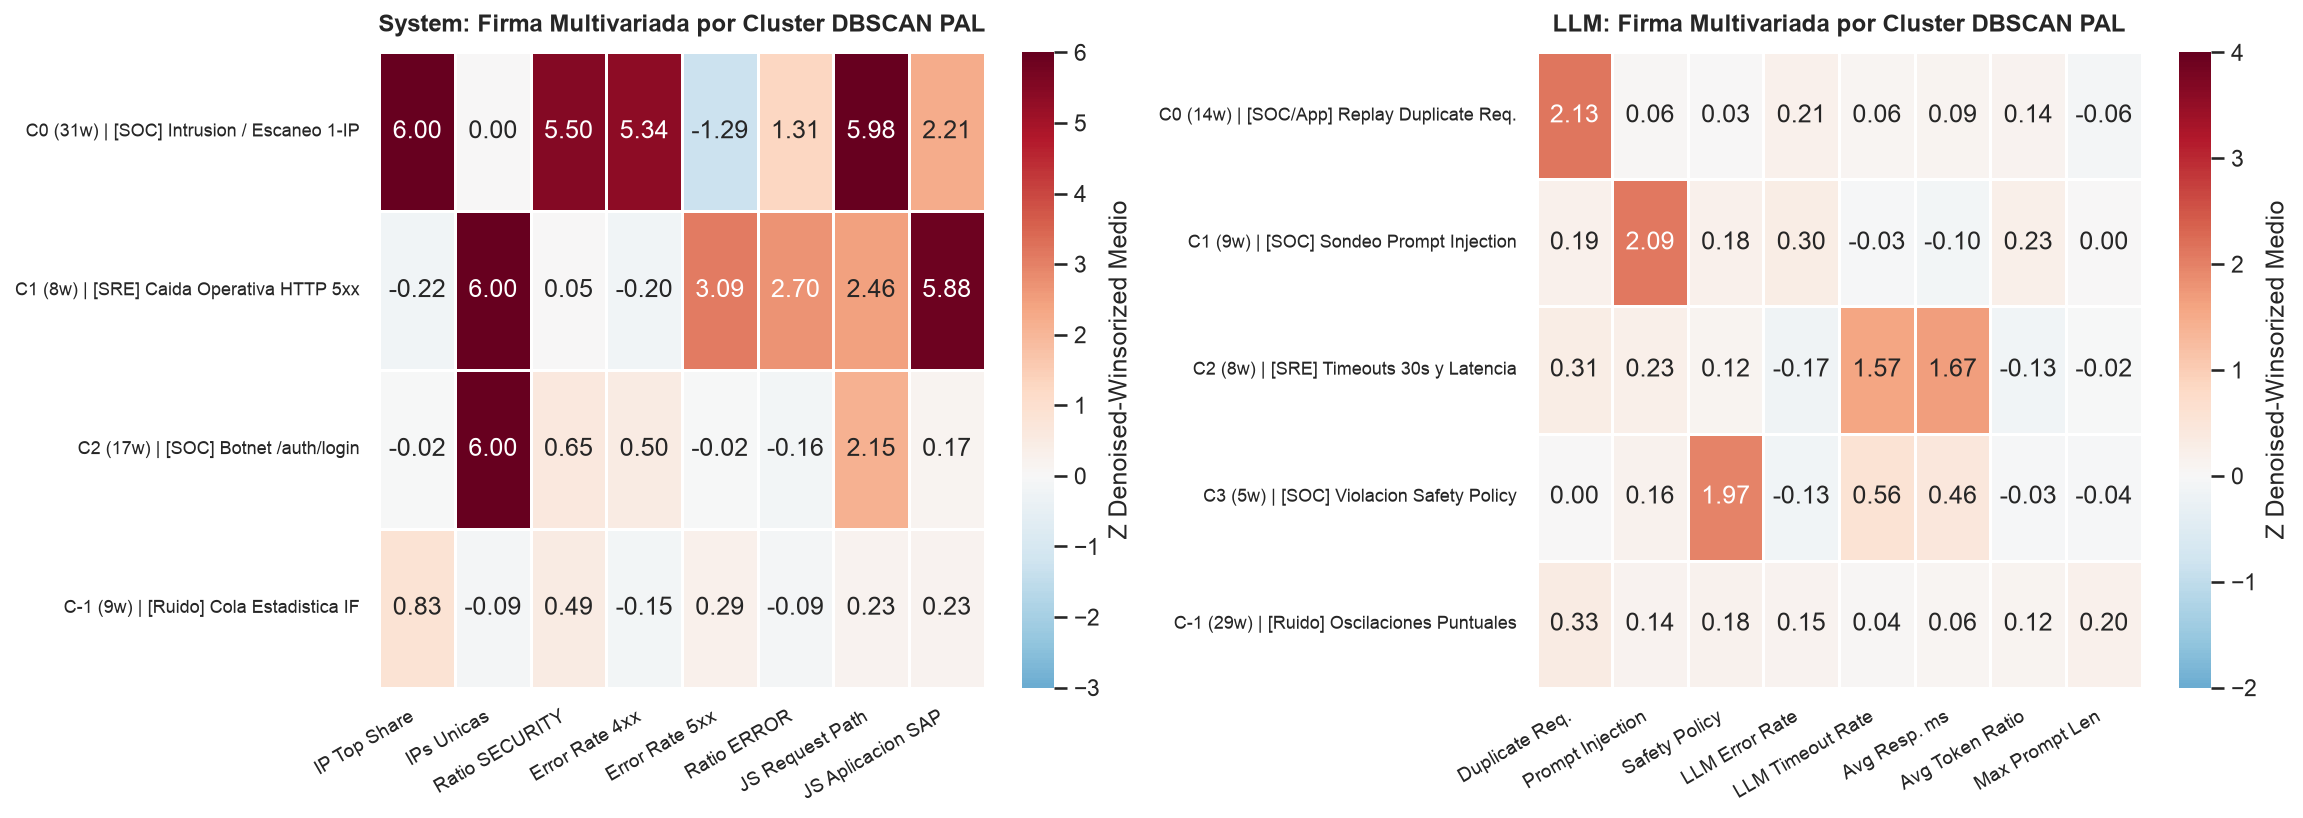

[OK] Resumen experimental exportado en: /Users/isaacmartinez/Documents/BloqueAD26/RetoSAP/sandbox/outputs_octubre/clustering_dbscan_pal_octubre_2026.json
[OK] Tablas temporales liberadas y conexion a SAP HANA Cloud cerrada correctamente.


In [10]:
# --- FIGURA 5: HUELLA FORENSE MULTIVARIADA POR CLUSTER DBSCAN PAL (SYSTEM Y LLM) ---
fig, axes = plt.subplots(1, 2, figsize=(15.6, 5.6))

# Heatmap System: perfil medio Z_clean por cluster (incluyendo fila de Ruido -1 para contraste)
cols_viz_sys = [
    'IP_TOP_SHARE', 'UNIQUE_IPS_COUNT', 'RATIO_SECURITY', 'ERROR_RATE_400',
    'ERROR_RATE_500', 'RATIO_ERROR', 'JS_HEATHERS_REQUEST_PATH', 'JS_SAP_FUNCTION_APPLICATION'
]
nombres_viz_sys = [
    'IP Top Share', 'IPs Unicas', 'Ratio SECURITY', 'Error Rate 4xx',
    'Error Rate 5xx', 'Ratio ERROR', 'JS Request Path', 'JS Aplicacion SAP'
]
filas_h_sys, idx_h_sys = [], []
diag_map_sys = dict(zip(catalogo_sys_sql['CLUSTER_ID'], catalogo_sys_sql['DIAGNOSTICO_CLUSTER']))

for cid_s in sorted(set(an_sys_res['CLUSTER_ID']) - {-1}) + [-1]:
    m_s = (an_sys_res['CLUSTER_ID'] == cid_s).values
    filas_h_sys.append(Z_clean_sys.loc[m_s, cols_viz_sys].mean().values)
    if cid_s >= 0:
        d_txt = diag_map_sys[cid_s]
        if 'Intrusion' in d_txt:
            corto = '[SOC] Intrusion / Escaneo 1-IP'
        elif 'Tormenta' in d_txt:
            corto = '[SRE] Caida Operativa HTTP 5xx'
        else:
            corto = '[SOC] Botnet /auth/login'
        idx_h_sys.append(f"C{cid_s} ({m_s.sum()}w) | {corto}")
    else:
        idx_h_sys.append(f"C-1 ({m_s.sum()}w) | [Ruido] Cola Estadistica IF")

sns.heatmap(
    pd.DataFrame(filas_h_sys, index=idx_h_sys, columns=nombres_viz_sys),
    annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-3.0, vmax=6.0,
    linewidths=0.7, cbar_kws={'label': 'Z Denoised-Winsorized Medio'}, ax=axes[0]
)
axes[0].set_title('System: Firma Multivariada por Cluster DBSCAN PAL', fontsize=11.3, fontweight='bold', pad=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right', fontsize=9)
axes[0].set_yticklabels(axes[0].get_yticklabels(), fontsize=8.8)

# Heatmap LLM: perfil medio Z_clean por cluster (K=4 + fila de Ruido -1)
cols_viz_llm = [
    'DUPLICATE_REQUEST_COUNT', 'INJECTION_COUNT', 'SAFETY_POLICY_COUNT',
    'LLM_ERROR_RATE', 'LLM_TIMEOUT_RATE', 'AVG_RESPONSE_TIME_MS',
    'AVG_TOKEN_RATIO', 'MAX_PROMPT_LENGTH'
]
nombres_viz_llm = [
    'Duplicate Req.', 'Prompt Injection', 'Safety Policy',
    'LLM Error Rate', 'LLM Timeout Rate', 'Avg Resp. ms',
    'Avg Token Ratio', 'Max Prompt Len'
]
filas_h_llm, idx_h_llm = [], []
feat_map_llm = dict(zip(catalogo_llm_sql['CLUSTER_ID'], catalogo_llm_sql['FEATURE_DOMINANTE']))
corto_map_llm = {
    'DUPLICATE_REQUEST_COUNT': '[SOC/App] Replay Duplicate Req.',
    'INJECTION_COUNT': '[SOC] Sondeo Prompt Injection',
    'LLM_TIMEOUT_RATE': '[SRE] Timeouts 30s y Latencia',
    'AVG_RESPONSE_TIME_MS': '[SRE] Timeouts 30s y Latencia',
    'SAFETY_POLICY_COUNT': '[SOC] Violacion Safety Policy',
}

for cid_l in sorted(set(an_llm_res['CLUSTER_ID']) - {-1}) + [-1]:
    m_l = (an_llm_res['CLUSTER_ID'] == cid_l).values
    filas_h_llm.append(Z_clean_llm.loc[m_l, cols_viz_llm].mean().values)
    if cid_l >= 0:
        f_dom_l = feat_map_llm.get(cid_l, '')
        corto_l = corto_map_llm.get(f_dom_l, f'[LLM] {f_dom_l}')
        idx_h_llm.append(f"C{cid_l} ({m_l.sum()}w) | {corto_l}")
    else:
        idx_h_llm.append(f"C-1 ({m_l.sum()}w) | [Ruido] Oscilaciones Puntuales")

sns.heatmap(
    pd.DataFrame(filas_h_llm, index=idx_h_llm, columns=nombres_viz_llm),
    annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-2.0, vmax=4.0,
    linewidths=0.7, cbar_kws={'label': 'Z Denoised-Winsorized Medio'}, ax=axes[1]
)
axes[1].set_title('LLM: Firma Multivariada por Cluster DBSCAN PAL', fontsize=11.3, fontweight='bold', pad=10)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right', fontsize=9)
axes[1].set_yticklabels(axes[1].get_yticklabels(), fontsize=8.8)

fig.tight_layout()
plt.show()

# Exportacion limpia del resumen JSON y limpieza de tablas temporales en SAP HANA Cloud
out_dir = 'outputs_octubre'
os.makedirs(out_dir, exist_ok=True)
resumen_export = {
    'auditoria_hana_pal': {
        'algoritmo_seleccionado': 'hana_ml.algorithms.pal.clustering.DBSCAN',
        'hdbscan_estado': 'No soportado en pal-service (_SYS_AFL.AFLPAL:HDBSCAN_ANY) y sin metrica coseno',
        'parametros_canonicos': {
            'metric': 'cosine',
            'minpts': MINPTS_DEFAULT,
            'tau_denoise': TAU_DENOISE,
            'clip_z': CLIP_Z_MAX,
            'max_cosine_eps_cap': MAX_COSINE_EPS,
            'eps_auto_system': eps_sys,
            'eps_auto_llm': eps_llm,
        },
    },
    'comparativa_metricas_pal': comp_metricas.to_dict(orient='records'),
    'experimento_k_dinamico_system': df_k_dinamico.to_dict(orient='records'),
    'experimento_streaming_zeroday_w0_a_w1': [
        {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in row.items()}
        for row in df_zeroday_w1.to_dict(orient='records')
    ],
    'catalogo_forense_system': catalogo_sys_sql.to_dict(orient='records'),
    'catalogo_forense_llm': catalogo_llm_sql.to_dict(orient='records'),
}

def _json_safe(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return str(obj)

ruta_json = os.path.join(out_dir, 'clustering_dbscan_pal_octubre_2026.json')
with open(ruta_json, 'w', encoding='utf-8') as f:
    json.dump(resumen_export, f, ensure_ascii=False, indent=2, default=_json_safe)

for tbl_tmp in ('#WIN_SYSTEM', '#WIN_LLM', '#PAL_DBSCAN_SYS_OCT', '#PAL_DBSCAN_LLM_OCT'):
    ventanas.drop_temp(conn, tbl_tmp)
conn.close()

print(f"[OK] Resumen experimental exportado en: {os.path.abspath(ruta_json)}")
print("[OK] Tablas temporales liberadas y conexion a SAP HANA Cloud cerrada correctamente.")

## 7. Conclusiones y Recomendación de Arquitectura para el Pipeline Final del Equipo

1. **`DBSCAN` (`metric='cosine', save_model=True`) es el reemplazo nativo óptimo en SAP HANA Cloud PAL:** Mientras que `HDBSCAN` está bloqueado a nivel servidor por `pal-service` (`AFLPAL:HDBSCAN_ANY`) y carece de métrica Coseno, **`DBSCAN` corre nativamente en HANA PAL**, soporta distancia Coseno directa y habilita inferencia `.predict()` con distancias continuas al núcleo.
2. **Solución unificada para las Secciones 5, 6 y 7 de `demo_pipeline_adrian.ipynb`:** Al reemplazar el filtro rígido `Z_UMBRAL = 5` y `KMeans` por **Z-Score *Denoised-Winsorized* ($\tau=1.5$, $C=6.0$) + Calibración Automática *Kneedle* + `DBSCAN` PAL**:
   - En **System (`65` ventanas / `14` eventos)**: Descubre automáticamente **$K = 3$** familias puras (`Intrusión/Escaneo 1-IP`, `Caída SRE 5xx` y `Botnet Distribuida /auth/login`), eleva el Coeficiente de Silueta Coseno respecto a `KMeans` y envía exactamente **7 de 7 eventos benignos** a `CLUSTER_ID = -1` (incluyendo los falsos positivos con $|Z| > 5$ que burlaban `Z_UMBRAL = 5`).
   - En **LLM (`65` ventanas / `60` eventos)**: Rescata el flujo que quedaba en **0 eventos** con `Z_UMBRAL = 5`, aislando automáticamente `29` ventanas de ruido estadístico en `CLUSTER_ID = -1` y agrupando las `36` ventanas relevantes en **$K = 4$ arquetipos accionables** (`Duplicate Request Replay`, `Prompt Injection`, `Timeouts SRE 30s` y `Safety Policy Violations`).
3. **$K$ Dinámico Real y Capacidad *Zero-Day*:** El experimento por lotes demostró adaptación automática **$K = 2$ (Semana 0) $\to K = 2$ (Semana 1) $\to K = 3$ (Mes Completo)** sin tocar hiperparámetros, mientras que `DBSCAN.predict()` distinguió en modo *streaming* ataques conocidos (`Evento 13`, $d_{\text{core}} = 0.0049$), ruido puntual (`Evento 14`) y campañas *Zero-Day* nunca vistas (`Eventos 11 y 12`, *Botnet* de 270 IPs).